# Recall-first prediction of death during follow-up in TCGA-BRCA, with a Black-vs-White fairness audit

**MSc project, Dept. of Computer Science, University of Jos** - *Utilizing SHAP to explain XGBoost for breast cancer*.
Implementation phase, version 2: new target (death during follow-up), data from `data/data_clinical_patient.csv`, recall-first operating point, and a bias-mitigation study.

The notebook calls the same `brca_xai` package that `run_pipeline.py` and the dashboard use, so numbers here equal the thesis numbers.
Runtime: about 4-5 minutes. Interpretation sentences below are *generated from the results*, never typed in.

| Section | Question |
|---|---|
| 1 | Who is in the cohort? |
| 2 | Which columns may a model use? (leakage and informative missingness) |
| 3 | How good is the model and what does recall-first cost? |
| 4 | Does it treat Black and White patients equally? Does mitigation help? |
| 5 | Are the conclusions robust? |
| 6 | What does the model look at (SHAP), and does it differ by race? |
| 7 | Save artifacts and figures |

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from brca_xai import data as D, modeling as M, fairness as F, plots
from brca_xai.pipeline import Study, FIG
s = Study()
def show(name, w=800): display(Image(filename=str(FIG / name), width=w))
def say(t): display(Markdown(t))

## 1. Cohort

In [2]:
s.load()
say(f"**{s.res['flow']['n_records']}** records -> remove {s.res['flow']['n_missing_race']} without race and {s.res['flow']['n_other_race']} Asian / other -> "
    f"**{s.res['flow']['n_cohort']}** White ({s.res['flow']['n_white']}) and Black ({s.res['flow']['n_black']}) patients, "
    f"**{s.res['flow']['deaths']}** deaths ({s.res['flow']['deaths_white']} White, {s.res['flow']['deaths_black']} Black). "
    f"Hold-out test set: {s.res['flow']['n_test']} patients, only **{s.res['flow']['test_black_deaths']}** Black deaths.")
display(s.table1)

**1084** records -> remove 90 without race and 61 Asian / other -> **933** White (751) and Black (182) patients, **141** deaths (111 White, 30 Black). Hold-out test set: 187 patients, only **6** Black deaths.

,characteristic,White,Black
0,"Patients, n",751,182
1,"Deaths during follow-up, n (%)",111 (14.8%),30 (16.5%)
2,"Age, median (IQR)",59 (49-67),54 (47-67)
3,"Follow-up months, median (IQR)",32 (17-62),27 (15-54)
4,T1,209 (28%),50 (27%)
5,T2,419 (56%),105 (58%)
6,T3,100 (13%),19 (10%)
7,T4,22 (3%),6 (3%)
8,N0,356 (47%),89 (49%)
9,N1,249 (33%),60 (33%)


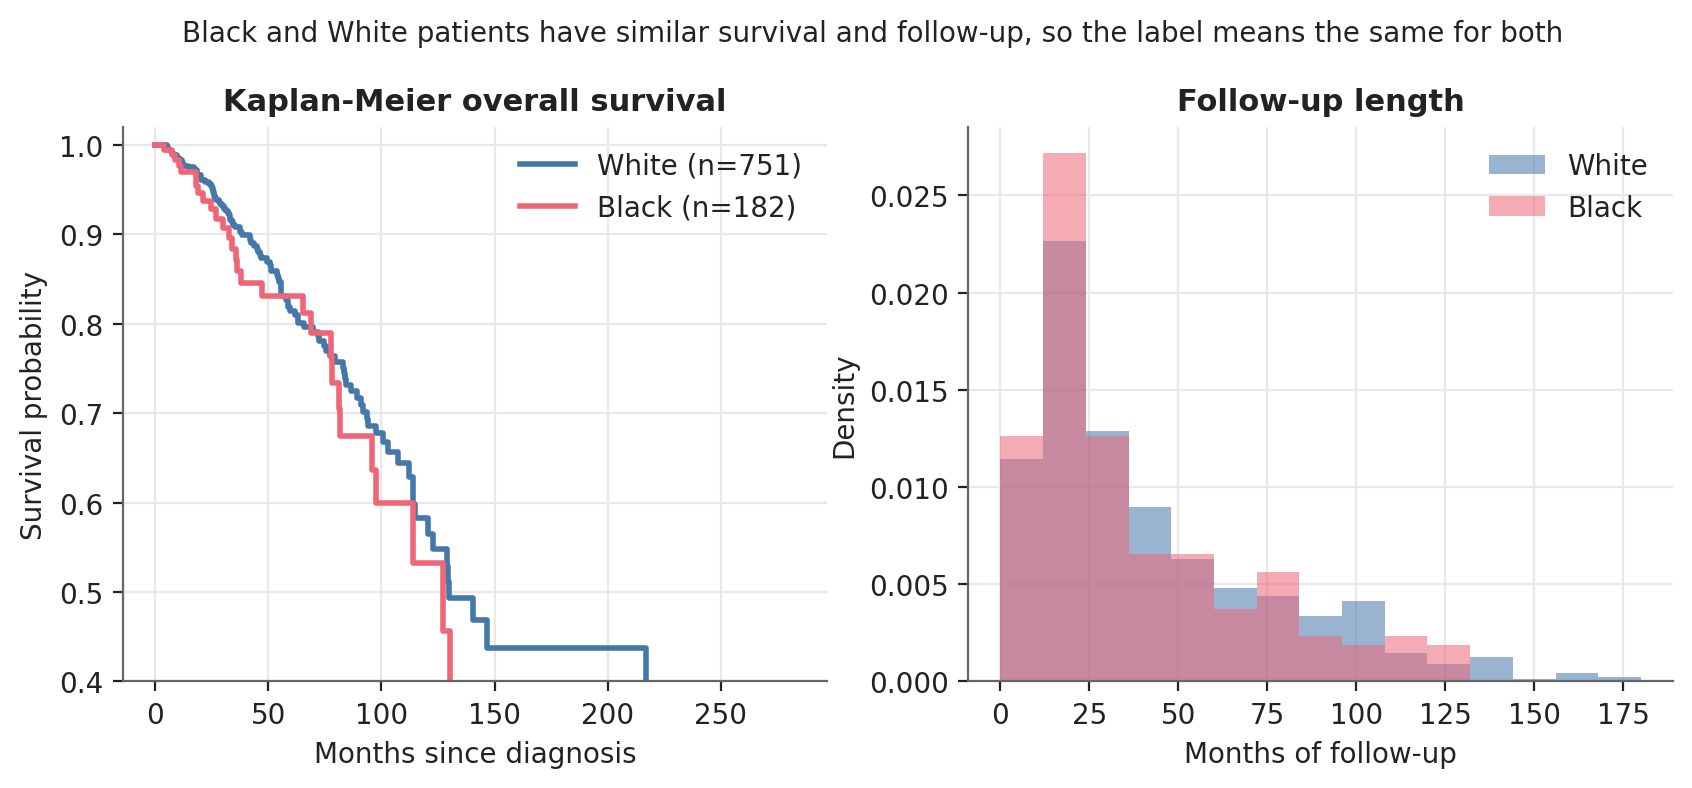

In [3]:
plots.fig_followup(s, FIG); show("01_survival_followup.png", 900)

## 2. Data governance: which columns may a model use?

Every one of the 38 source columns gets an explicit decision. Two traps in this table:
* **Leakage** - follow-up time, other survival endpoints, tumour status at follow-up.
* **Informative missingness** - a blank that predicts death (registry artefact, not biology).

In [4]:
display(s.governance.groupby("decision").size().to_frame("columns"))
display(s.governance)

,columns
decision,
Excluded: informative missingness,4
Excluded: no signal / redundant,13
Excluded: outcome leakage / post-baseline,12
Kept as model input,8
Target,1


,column,decision,reason
0,OS_MONTHS,Excluded: outcome leakage / post-baseline,the follow-up time that defines the outcome
1,DAYS_LAST_FOLLOWUP,Excluded: outcome leakage / post-baseline,follow-up time; blank for 100 % of deaths in the cohort (another label)
2,DSS_STATUS,Excluded: outcome leakage / post-baseline,disease-specific death: a subset of the outcome
3,DSS_MONTHS,Excluded: outcome leakage / post-baseline,survival time
4,DFS_STATUS,Excluded: outcome leakage / post-baseline,recurrence after treatment: only known after follow-up
5,DFS_MONTHS,Excluded: outcome leakage / post-baseline,survival time
6,PFS_STATUS,Excluded: outcome leakage / post-baseline,progression: only known after follow-up
7,PFS_MONTHS,Excluded: outcome leakage / post-baseline,survival time
8,PERSON_NEOPLASM_CANCER_STATUS,Excluded: outcome leakage / post-baseline,"tumour status at last follow-up (post-baseline, outcome proxy)"
9,NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT,Excluded: outcome leakage / post-baseline,"post-treatment event (post-baseline, outcome proxy)"


In [5]:
display(s.missingness.round(3))

,column,n_missing,pct_missing,death_rate_missing,death_rate_recorded
0,SUBTYPE,96,10.289,0.198,0.146
1,RADIATION_THERAPY,71,7.610,0.563,0.117
2,ETHNICITY,81,8.682,0.037,0.162
3,PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT,266,28.510,0.173,0.142
4,PERSON_NEOPLASM_CANCER_STATUS,111,11.897,0.216,0.142
5,NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT,155,16.613,0.323,0.117
6,AJCC_STAGING_EDITION,134,14.362,0.119,0.156
7,DAYS_LAST_FOLLOWUP,98,10.504,1.000,0.051
8,PATH_N_STAGE = NX,18,1.929,0.611,0.142
9,PATH_M_STAGE = MX,154,16.506,0.091,0.163


## 3. Model development

In [6]:
s.tune()
say(f"Selected hyper-parameters: max_depth={s.params['max_depth']}, n_estimators={s.params['n_estimators']}, learning_rate={s.params['learning_rate']:.3f}")
display(s.tuning.head(8)[["max_depth", "n_estimators", "learning_rate", "auc", "fpr_at_80_recall"]].round(3))

[20:00:35] tuning hyper-parameters on the development set ...


Selected hyper-parameters: max_depth=1, n_estimators=377, learning_rate=0.019

,max_depth,n_estimators,learning_rate,auc,fpr_at_80_recall
0,1,377,0.019,0.651,0.618
1,3,229,0.011,0.623,0.623
2,2,353,0.011,0.631,0.626
3,1,112,0.126,0.654,0.628
4,2,196,0.025,0.642,0.632
5,1,103,0.049,0.638,0.632
6,1,306,0.072,0.642,0.634
7,3,112,0.061,0.632,0.636


[20:00:50] leakage ladder and model benchmark ...


,rung,note,auc,fpr_at_80_recall
0,0 Clean pre-treatment features (used),"Age, T, N (NX->N0), M (MX->M0), PAM50, histology, prior diagnosis",0.657,0.596
1,1 + NX / MX left as 'missing',Registry 'not assessed' codes: NX has a 61 % death rate,0.678,0.560
2,"2 + radiation, ethnicity, node-assessment (informative missingness)",Their blanks track the outcome (56 % vs 12 % for radiation),0.755,0.514
3,3 + tumour status & new-tumour event at follow-up (post-baseline),Outcome proxies recorded after diagnosis,0.859,0.303
4,4 + days to last follow-up,Blank for every patient who died,0.914,0.080


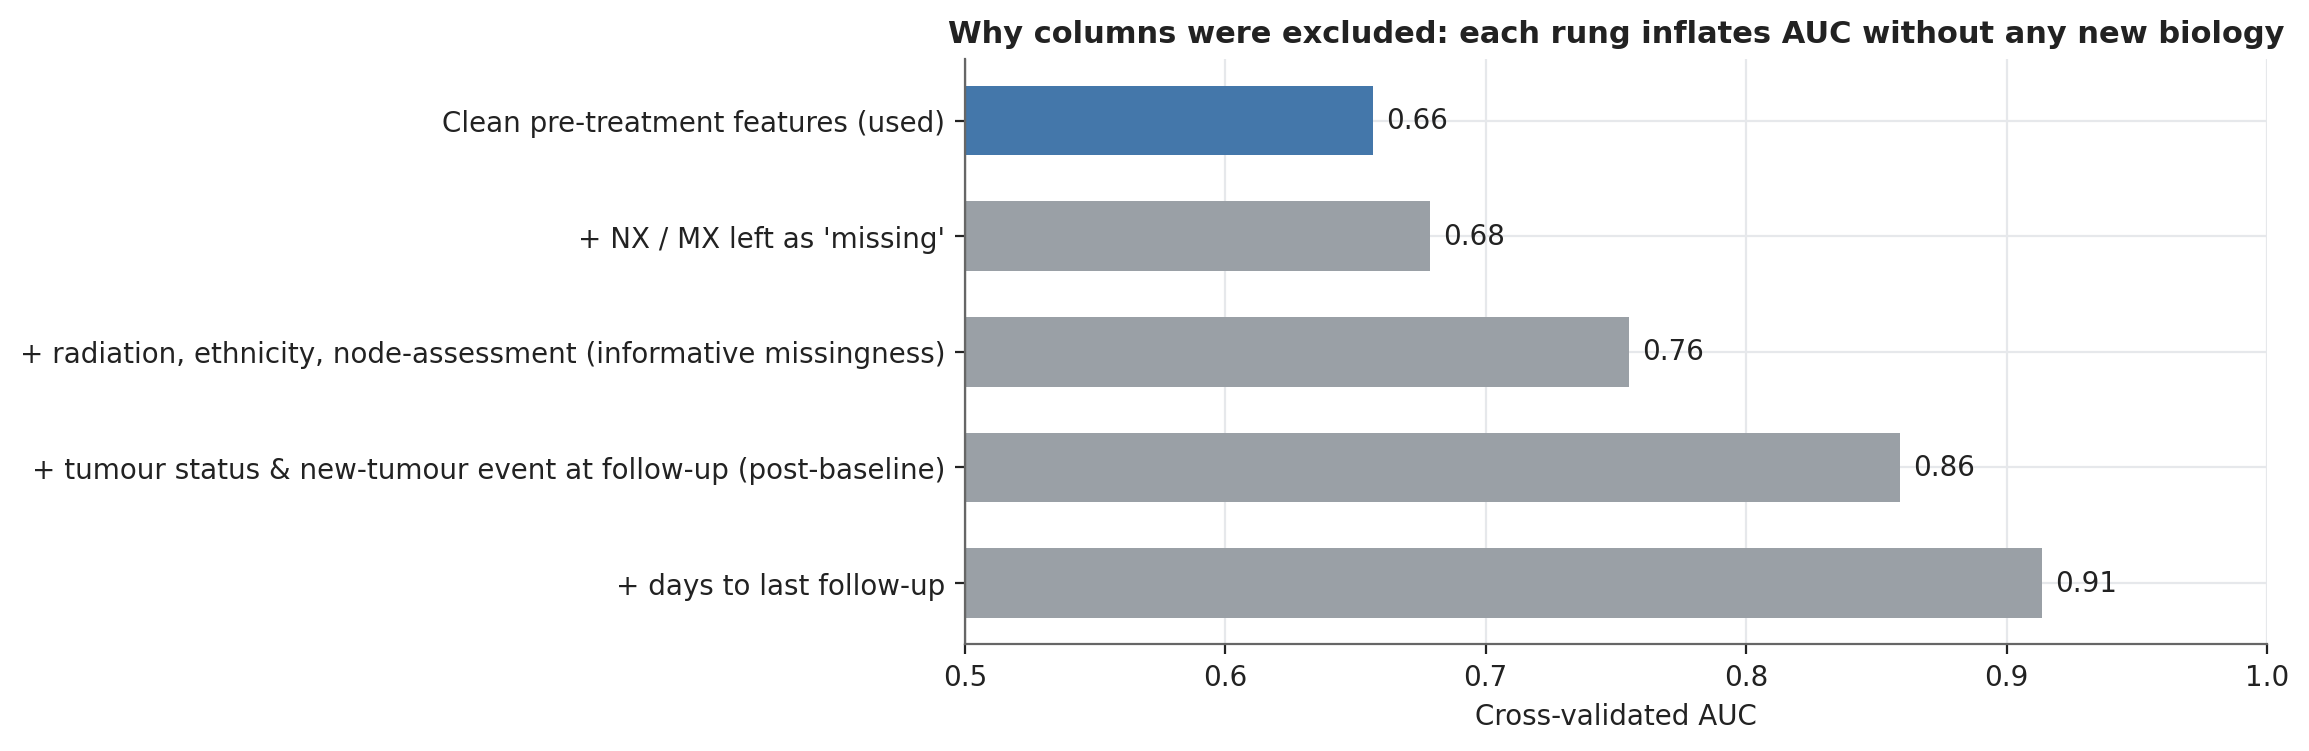

In [7]:
s.audit_models()
display(s.ladder[["rung", "note", "auc", "fpr_at_80_recall"]].round(3))
plots.fig_leakage(s, FIG); show("02_leakage_ladder.png", 800)

,model,auc,auc_sd,fpr_at_80_recall,auc_White,auc_Black
0,Logistic regression,0.619,0.008,0.722,0.634,0.560
1,Random forest,0.626,0.009,0.654,0.646,0.555
2,"XGBoost (defaults, monotone TNM)",0.645,0.013,0.586,0.657,0.596
3,"XGBoost (tuned, no monotone constraint)",0.657,0.010,0.598,0.662,0.634
4,"XGBoost (tuned, monotone TNM) - used",0.657,0.009,0.596,0.662,0.634


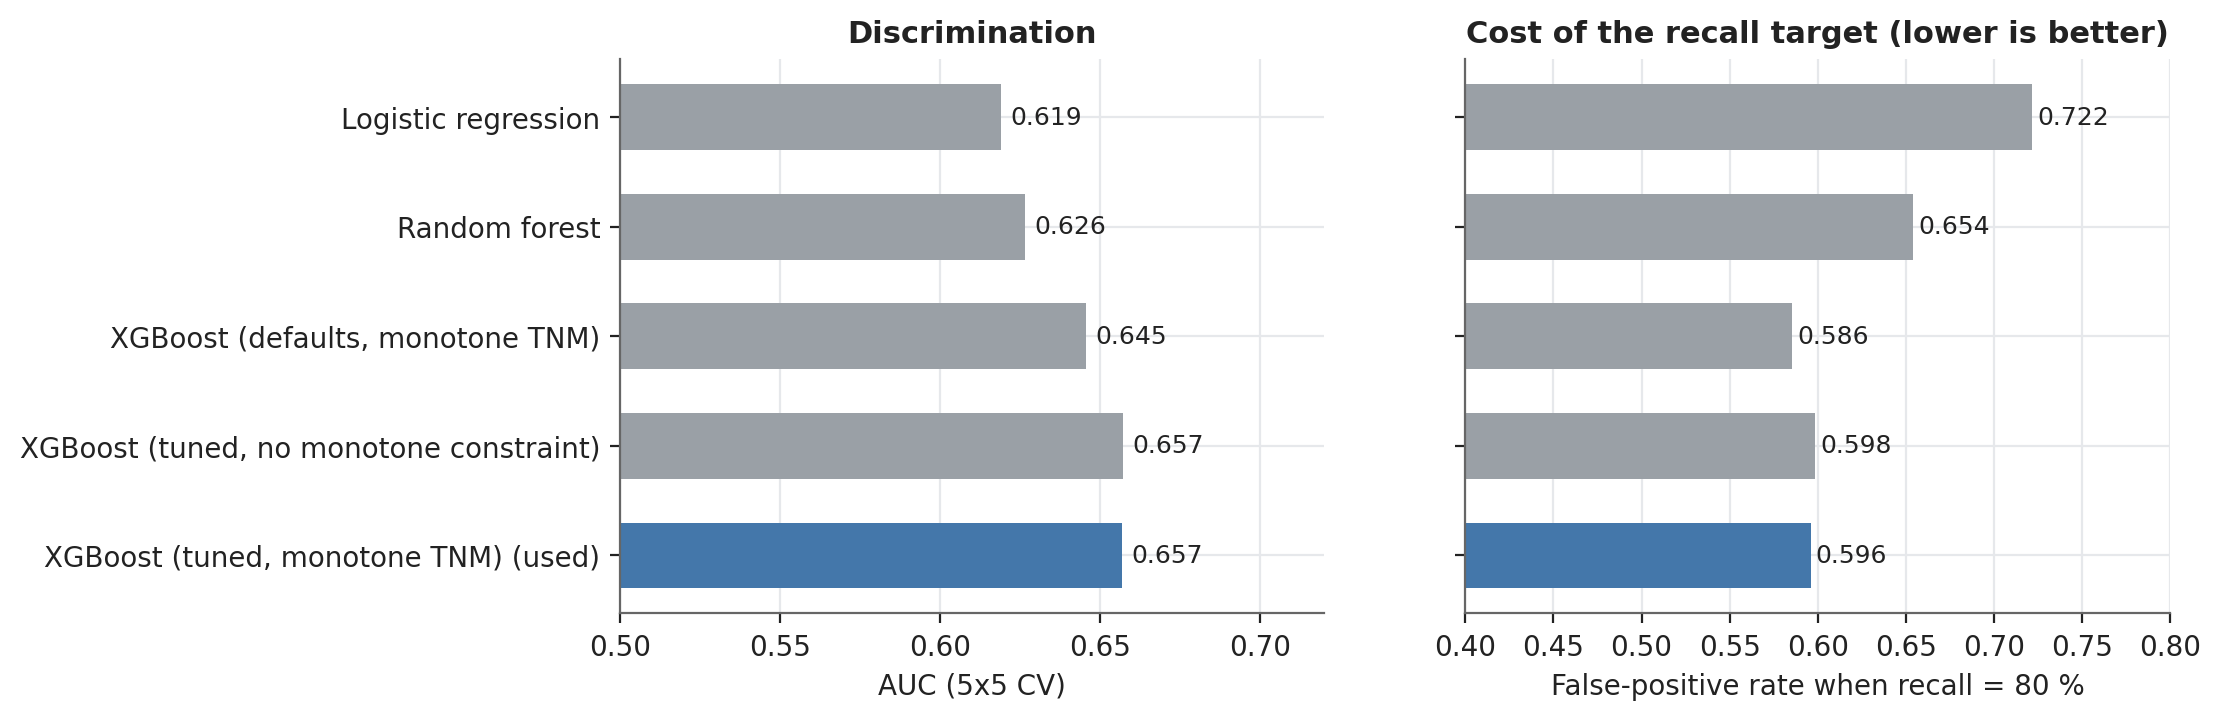

*Logistic regression, random forest and XGBoost reach similar AUC: the ceiling is set by the information in clinical covariates, not by the algorithm.*

In [8]:
display(s.bench.round(3))
plots.fig_benchmark(s, FIG); show("03_model_benchmark.png", 900)
say("*Logistic regression, random forest and XGBoost reach similar AUC: the ceiling is set by the information in clinical covariates, not by the algorithm.*")

## 4. Recall-first evaluation on the untouched hold-out set

[20:01:38] hold-out evaluation ...


,strategy,group,n,deaths,recall,recall_lo,recall_hi,fpr,flag_rate,auc
0,aware,All,187,28,0.821,0.644,0.921,0.560,0.599,0.644
1,aware,White,150,22,0.773,0.566,0.899,0.547,0.580,0.621
2,aware,Black,37,6,1.000,0.610,1.000,0.613,0.676,0.763
3,blind,All,187,28,0.857,0.685,0.943,0.591,0.631,0.649
4,blind,White,150,22,0.818,0.615,0.927,0.578,0.613,0.627
5,blind,Black,37,6,1.000,0.610,1.000,0.645,0.703,0.766
6,reweigh,All,187,28,0.786,0.605,0.898,0.566,0.599,0.646
7,reweigh,White,150,22,0.727,0.518,0.868,0.555,0.580,0.624
8,reweigh,Black,37,6,1.000,0.610,1.000,0.613,0.676,0.755
9,gthr,All,187,28,0.857,0.685,0.943,0.629,0.663,0.649


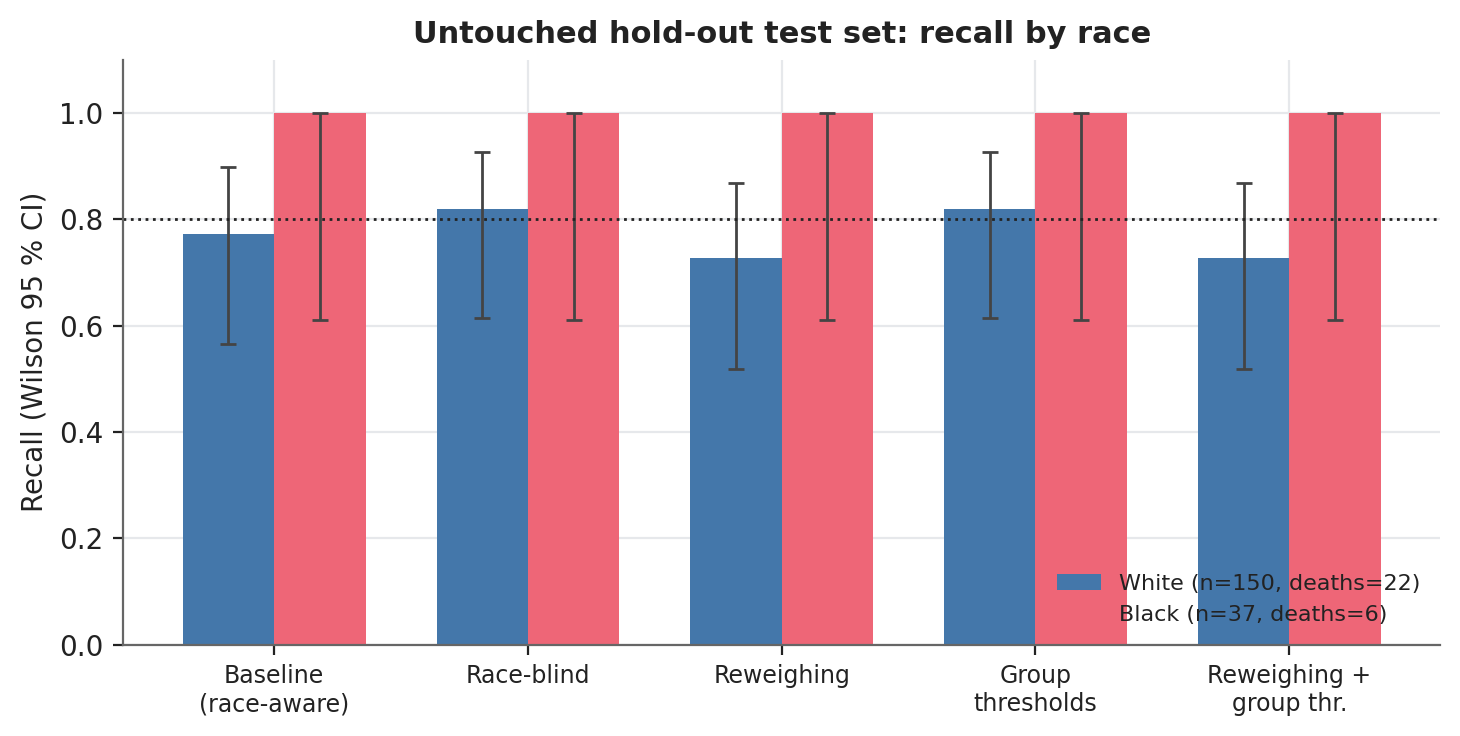

*Only 6 Black deaths are in this split - its group-level recall is an anecdote. The fairness conclusions come from the repeated cross-validation below.*

In [9]:
s.holdout()
display(s.holdout_table[["strategy", "group", "n", "deaths", "recall", "recall_lo", "recall_hi", "fpr", "flag_rate", "auc"]].round(3))
plots.fig_holdout(s, FIG); show("09_holdout_recall.png", 700)
say(f"*Only {s.res['flow']['test_black_deaths']} Black deaths are in this split - its group-level recall is an anecdote. The fairness conclusions come from the repeated cross-validation below.*")

## 5. Fairness audit: 5 strategies x 5 repeats x 5-fold CV, bootstrap intervals

Gap = Black minus White. **Recall gap** is equal opportunity (0 is fair). **False-alarm gap** > 0 means Black survivors are flagged more often.

In [10]:
s.fairness(); s.headline()
t = s.summary[s.summary.metric.isin(["tpr_W", "tpr_B", "tpr_gap", "fpr_W", "fpr_B", "fpr_gap", "eod", "flag_all"])]
t = t.assign(v=t.apply(lambda r: f"{r.estimate:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)).pivot(index="strategy", columns="metric", values="v")
display(t.loc[[x.key for x in M.STRATEGIES]])

[20:01:41] repeated 5x5-fold CV of all strategies ...


[20:01:51] bootstrap ...


metric,eod,flag_all,fpr_B,fpr_W,fpr_gap,tpr_B,tpr_W,tpr_gap
strategy,,,,,,,,
aware,"0.050 [0.018, 0.168]","0.652 [0.627, 0.677]","0.667 [0.603, 0.728]","0.617 [0.585, 0.649]","0.050 [-0.022, 0.120]","0.800 [0.667, 0.929]","0.795 [0.730, 0.859]","0.005 [-0.141, 0.156]"
blind,"0.042 [0.015, 0.173]","0.655 [0.630, 0.680]","0.664 [0.600, 0.726]","0.622 [0.590, 0.654]","0.042 [-0.030, 0.114]","0.800 [0.667, 0.929]","0.789 [0.720, 0.856]","0.011 [-0.134, 0.163]"
reweigh,"0.037 [0.014, 0.169]","0.657 [0.631, 0.683]","0.663 [0.599, 0.726]","0.626 [0.594, 0.659]","0.037 [-0.035, 0.109]","0.800 [0.667, 0.929]","0.791 [0.723, 0.855]","0.009 [-0.135, 0.161]"
gthr,"0.042 [0.018, 0.172]","0.667 [0.642, 0.692]","0.678 [0.616, 0.735]","0.635 [0.604, 0.667]","0.042 [-0.023, 0.110]","0.820 [0.693, 0.940]","0.796 [0.730, 0.860]","0.024 [-0.113, 0.164]"
reweigh_gthr,"0.029 [0.013, 0.167]","0.674 [0.650, 0.699]","0.675 [0.614, 0.733]","0.646 [0.614, 0.678]","0.029 [-0.037, 0.096]","0.813 [0.680, 0.940]","0.802 [0.738, 0.866]","0.012 [-0.131, 0.156]"


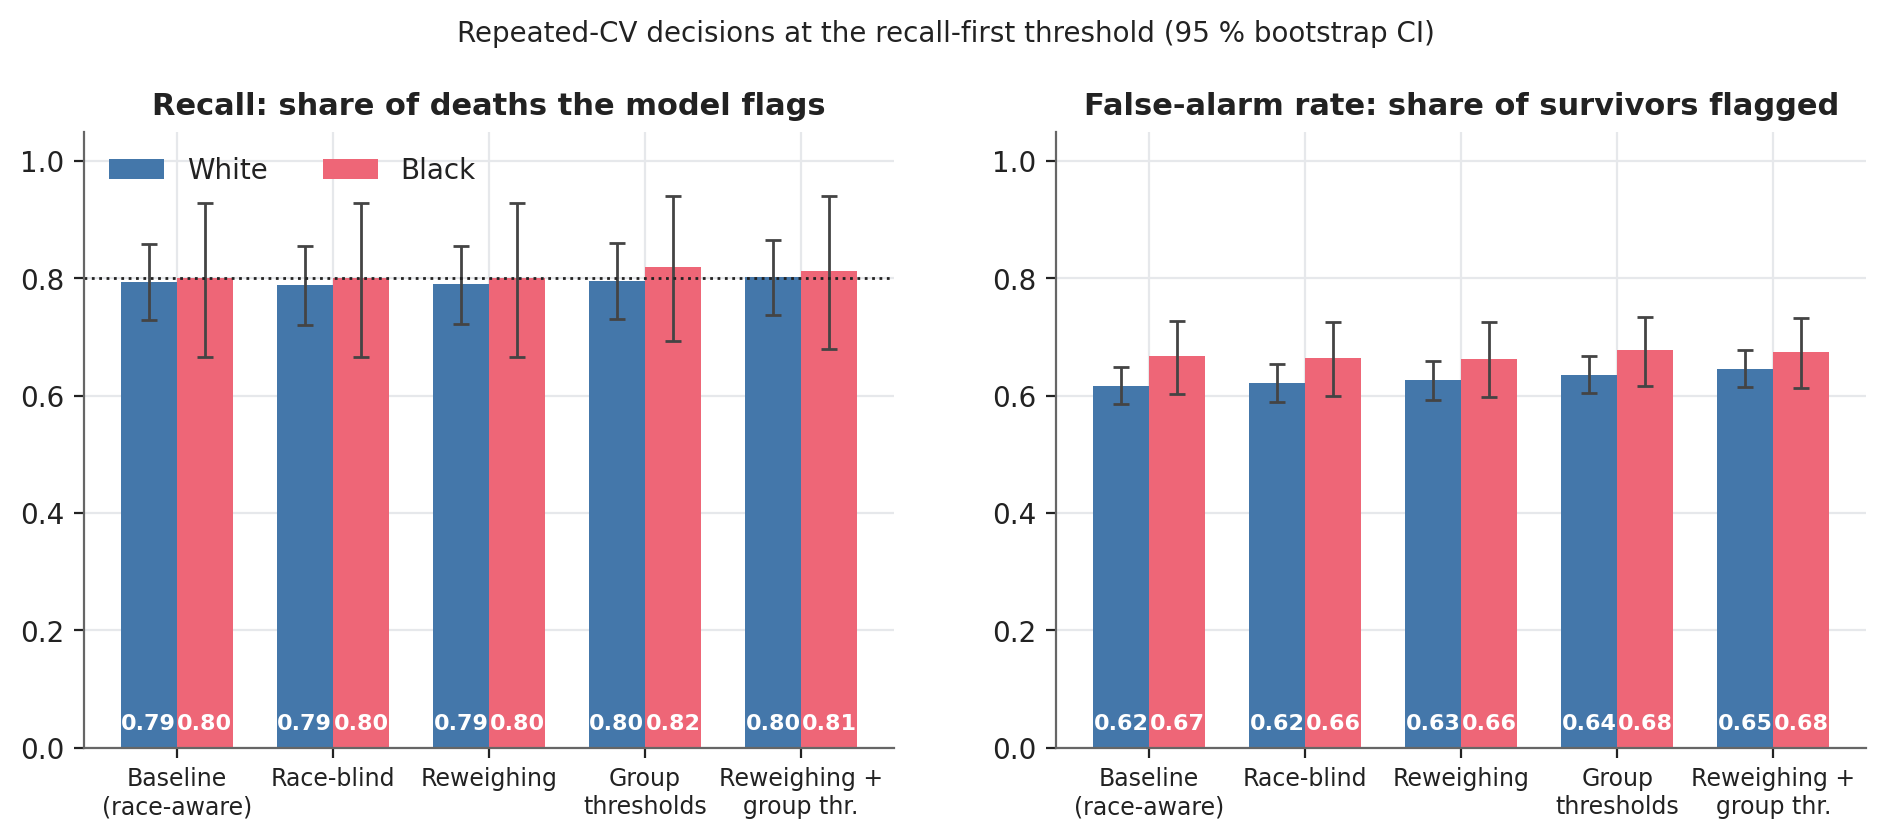

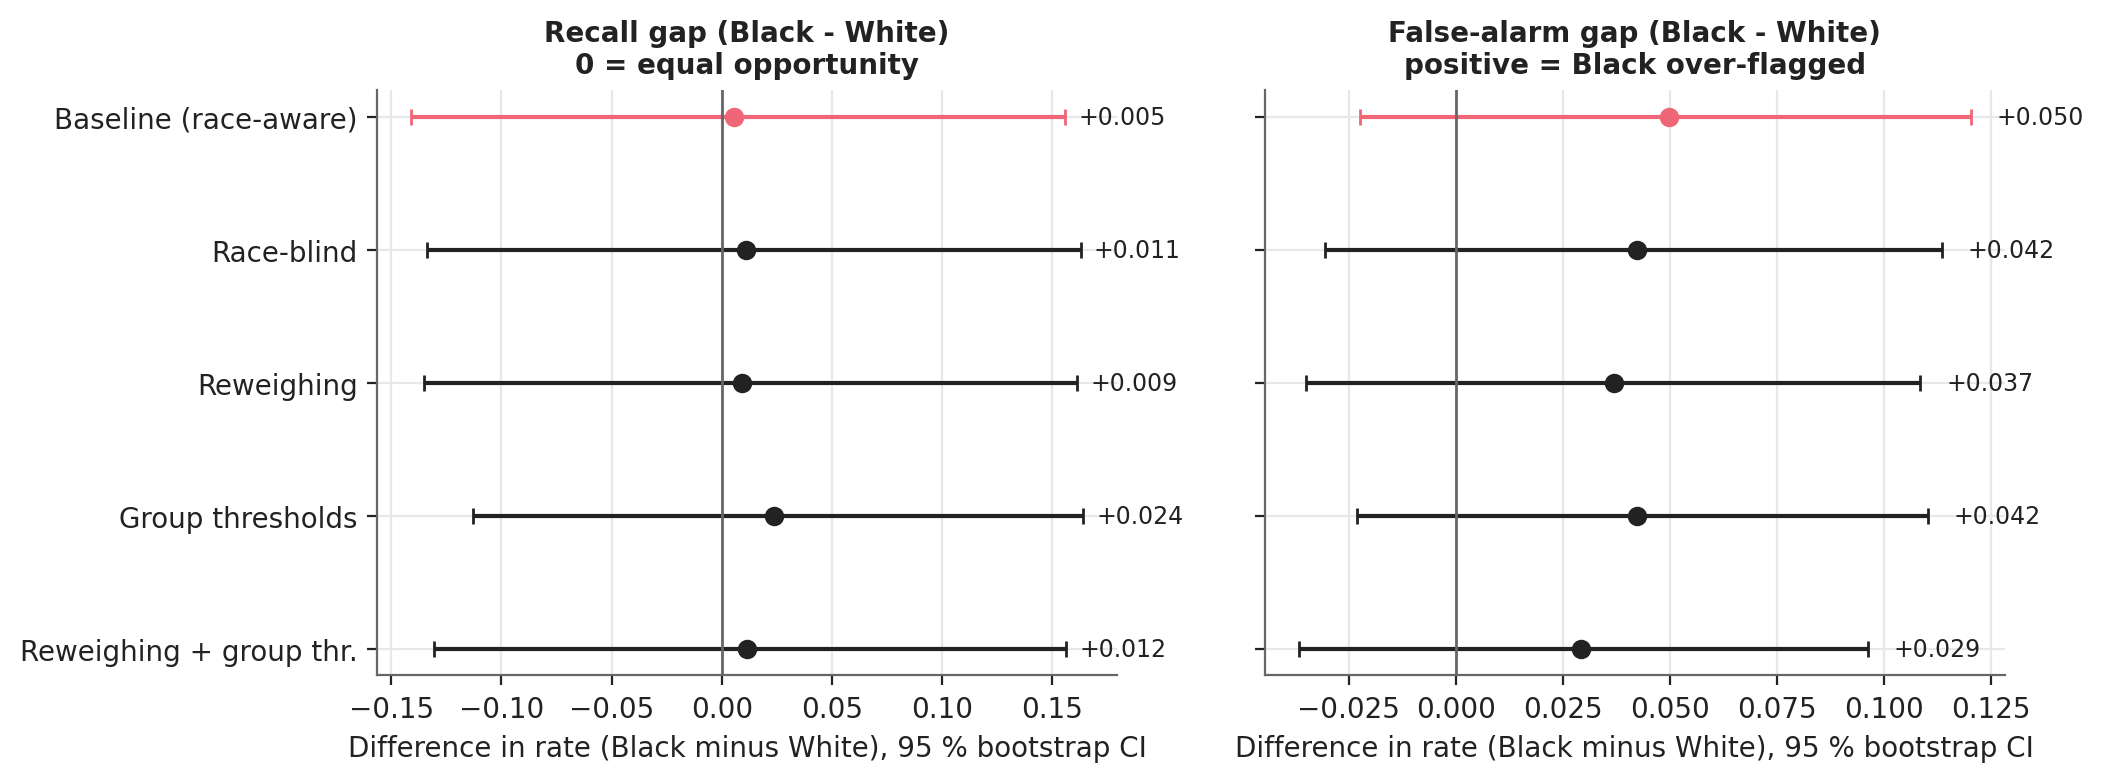

In [11]:
plots.fig_group_rates(s, FIG); show("05_rates_by_race.png", 1000)
plots.fig_gaps(s, FIG); show("06_gap_forest.png", 1000)

In [12]:
display(s.paired.round(3))
r = s.res["cv"]["aware"]
say(f"**Baseline:** recall gap {r['tpr_gap']:+.3f} (95% CI {r['tpr_gap_ci'][0]:+.3f} to {r['tpr_gap_ci'][1]:+.3f}); "
    f"false-alarm gap {r['fpr_gap']:+.3f} (CI {r['fpr_gap_ci'][0]:+.3f} to {r['fpr_gap_ci'][1]:+.3f}). "
    f"The recall CI is about +-{(r['tpr_gap_ci'][1]-r['tpr_gap_ci'][0])/2:.2f}: with {s.res['flow']['deaths_black']} Black deaths a gap of that size cannot be excluded.")

,strategy,metric,diff_vs_aware,lo,hi,prob_smaller
0,blind,tpr_gap,0.006,-0.003,0.014,0.066
1,blind,fpr_gap,-0.008,-0.019,0.005,0.889
2,blind,abs_tpr_gap,0.001,-0.011,0.014,0.382
3,blind,eod,-0.002,-0.016,0.013,0.586
4,reweigh,tpr_gap,0.004,-0.006,0.013,0.170
5,reweigh,fpr_gap,-0.013,-0.024,-0.001,0.982
6,reweigh,abs_tpr_gap,0.001,-0.011,0.012,0.383
7,reweigh,eod,-0.004,-0.021,0.012,0.632
8,gthr,tpr_gap,0.018,-0.006,0.051,0.106
9,gthr,fpr_gap,-0.007,-0.027,0.013,0.744


**Baseline:** recall gap +0.005 (95% CI -0.141 to +0.156); false-alarm gap +0.050 (CI -0.022 to +0.120). The recall CI is about +-0.15: with 30 Black deaths a gap of that size cannot be excluded.

,group,strategy,auc,lo,hi
0,All,aware,0.657,0.611,0.702
1,White,aware,0.660,0.601,0.717
2,Black,aware,0.645,0.535,0.749
3,All,blind,0.657,0.612,0.702
4,White,blind,0.660,0.599,0.716
5,Black,blind,0.646,0.537,0.750
6,All,reweigh,0.657,0.612,0.703
7,White,reweigh,0.660,0.600,0.717
8,Black,reweigh,0.646,0.538,0.750


,strategy,group,observed,mean_predicted,oe_ratio,slope,intercept,brier
0,aware,White,0.148,0.146,1.013,1.599,1.027,0.118
1,aware,Black,0.165,0.151,1.093,1.329,0.659,0.131
2,blind,White,0.148,0.146,1.013,1.606,1.038,0.118
3,blind,Black,0.165,0.150,1.096,1.329,0.662,0.131


,strategy,threshold,mean,sd,min,max
0,aware,global,0.118,0.004,0.112,0.125
1,aware,White,0.117,0.005,0.108,0.128
2,aware,Black,0.117,0.010,0.100,0.138
3,blind,global,0.118,0.004,0.112,0.125
4,blind,White,0.117,0.005,0.108,0.128
5,blind,Black,0.117,0.009,0.100,0.138
6,reweigh,global,0.118,0.004,0.111,0.126
7,reweigh,White,0.116,0.005,0.107,0.127
8,reweigh,Black,0.117,0.009,0.098,0.134
9,gthr,global,0.118,0.004,0.112,0.125


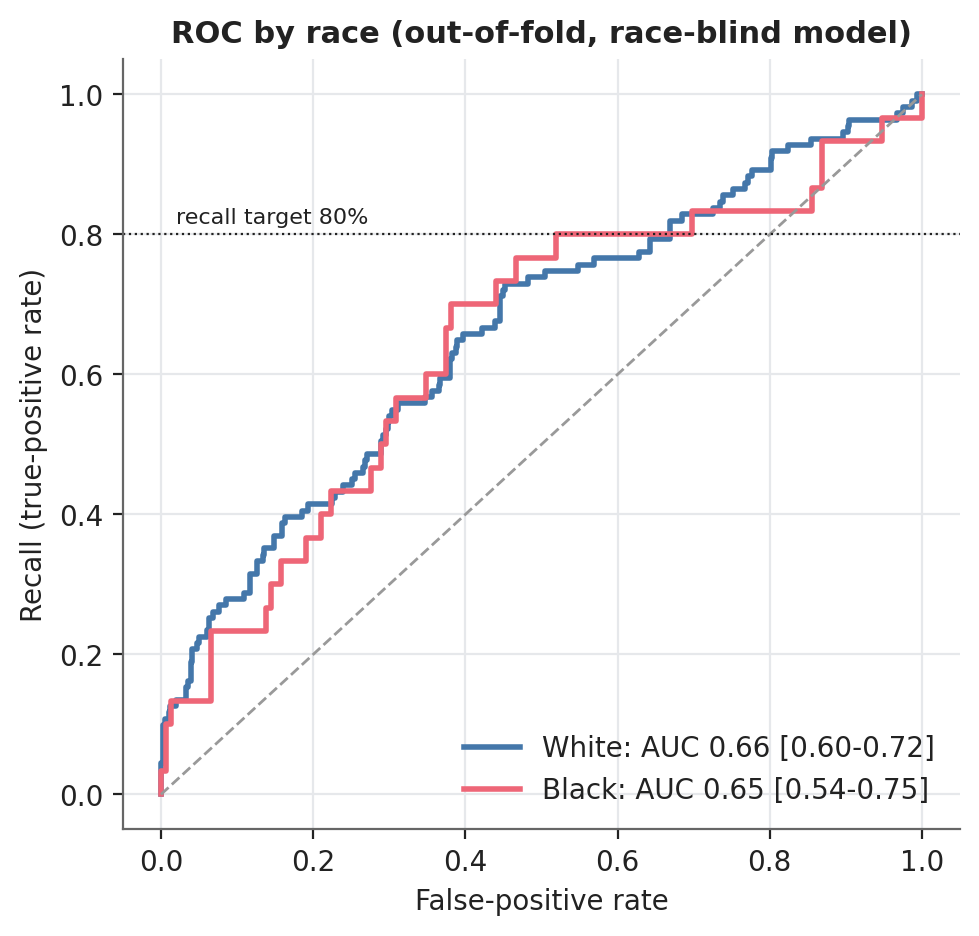

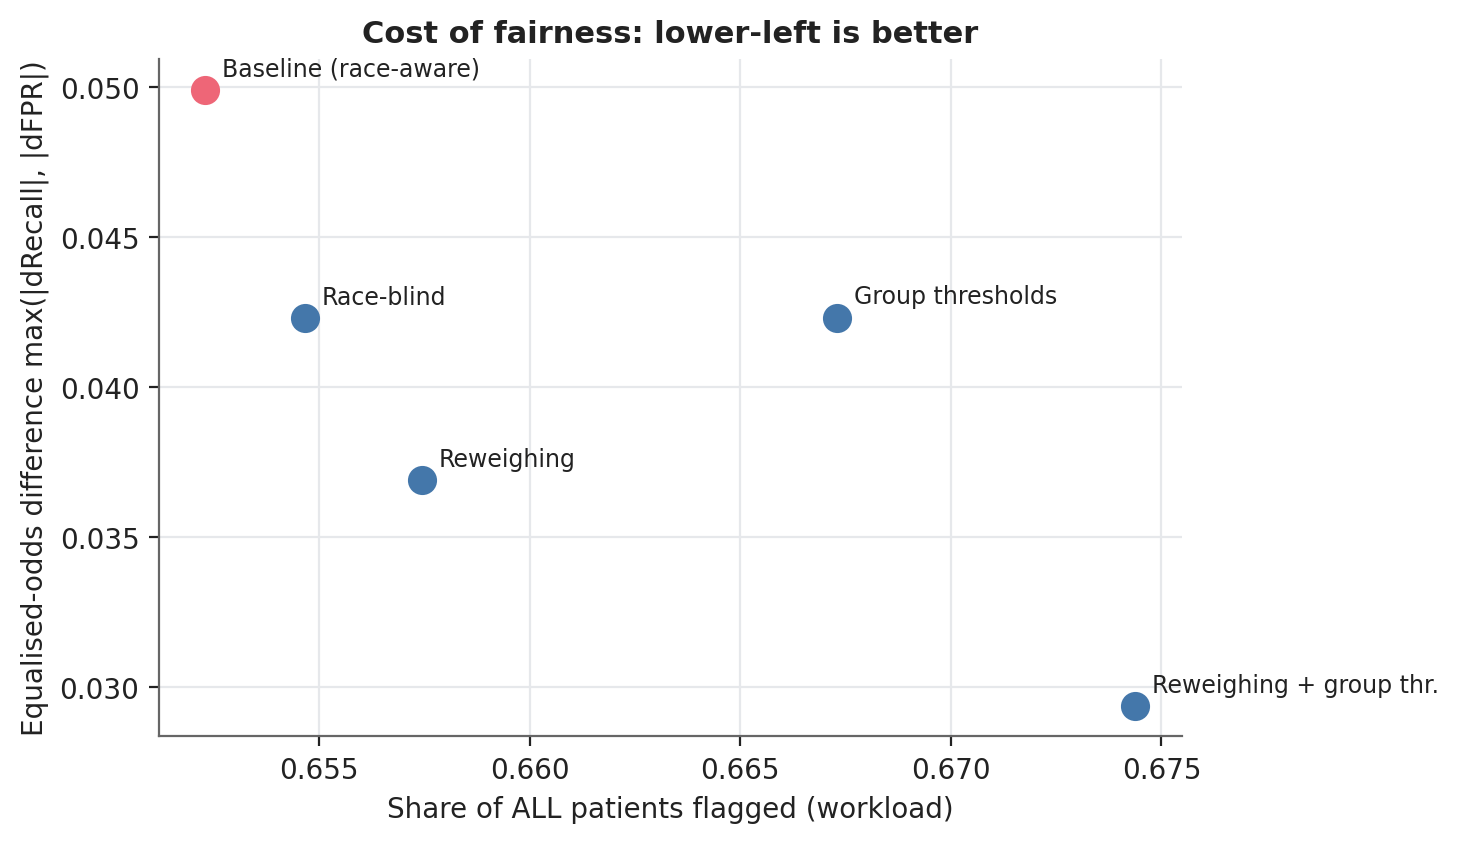

In [13]:
display(s.auc_group.round(3)); display(s.calibration.round(3))
display(s.cv_thresholds.round(3))
plots.fig_roc(s, FIG); show("04_roc_by_group.png", 450)
plots.fig_tradeoff(s, FIG); show("07_tradeoff.png", 550)

## 6. Robustness: recall target, settled outcomes, group definition

[20:02:13] recall-target sweep ...


target                 0.70   0.75   0.80   0.85   0.90   0.95
metric  strategy                                              
fpr_gap aware         0.024  0.025  0.053  0.072  0.069  0.031
        blind         0.024  0.014  0.051  0.071  0.067  0.041
        gthr         -0.025 -0.030  0.011  0.028  0.021  0.033
        reweigh       0.019  0.017  0.043  0.066  0.065  0.040
        reweigh_gthr -0.033 -0.036  0.026  0.026  0.018  0.033
tpr_gap aware         0.052  0.044  0.024  0.035  0.016 -0.011
        blind         0.055  0.061  0.035  0.037  0.013 -0.002
        gthr         -0.023  0.014  0.021 -0.008 -0.023 -0.013
        reweigh       0.029  0.055  0.024  0.034  0.008 -0.011
        reweigh_gthr -0.029 -0.011  0.027 -0.005 -0.023 -0.016

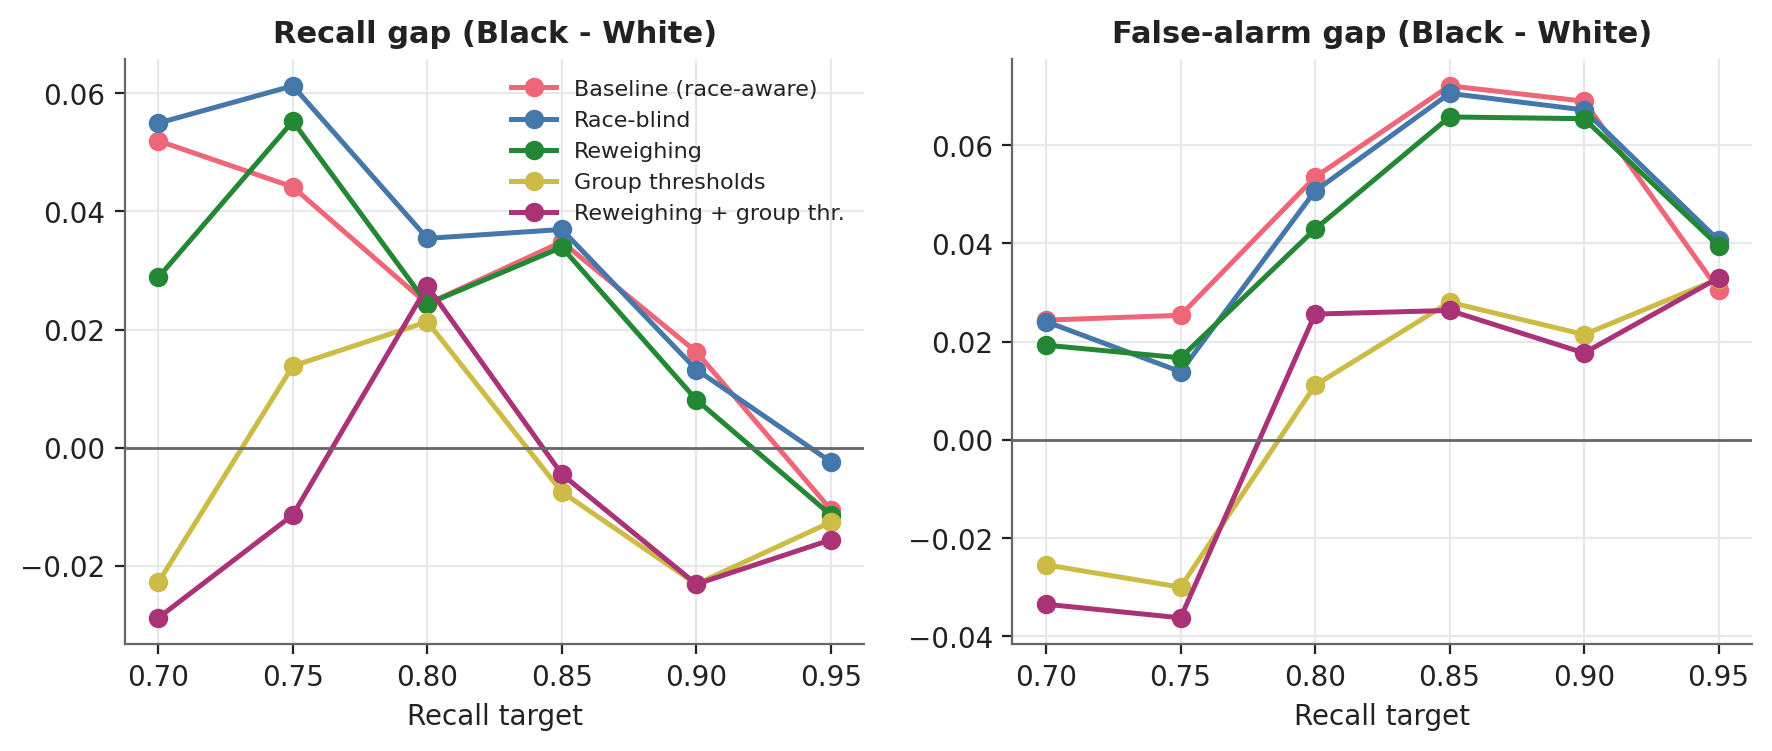

In [14]:
s.sweep()
display(s.sweep_table[s.sweep_table.metric.isin(["tpr_gap", "fpr_gap"])].pivot_table(index=["metric", "strategy"], columns="target", values="estimate").round(3))
plots.fig_sweep(s, FIG); show("08_recall_target_sweep.png", 950)

[20:02:58] sensitivity analyses ...


,strategy,metric,estimate,lo,hi,analysis
9,aware,tpr_gap,0.005,-0.177,0.133,"settled outcome (died or >= 24 mo follow-up), n=580"
10,aware,fpr_gap,0.095,-0.008,0.192,"settled outcome (died or >= 24 mo follow-up), n=580"
22,blind,tpr_gap,0.011,-0.176,0.141,"settled outcome (died or >= 24 mo follow-up), n=580"
23,blind,fpr_gap,0.079,-0.018,0.181,"settled outcome (died or >= 24 mo follow-up), n=580"
35,reweigh,tpr_gap,0.009,-0.177,0.137,"settled outcome (died or >= 24 mo follow-up), n=580"
36,reweigh,fpr_gap,0.078,-0.023,0.175,"settled outcome (died or >= 24 mo follow-up), n=580"
74,aware,tpr_gap,0.005,-0.129,0.144,"settled outcome (died or >= 36 mo follow-up), n=464"
75,aware,fpr_gap,0.136,0.024,0.246,"settled outcome (died or >= 36 mo follow-up), n=464"
87,blind,tpr_gap,0.011,-0.126,0.153,"settled outcome (died or >= 36 mo follow-up), n=464"
88,blind,fpr_gap,0.124,0.011,0.234,"settled outcome (died or >= 36 mo follow-up), n=464"


,strategy,group,n,deaths,recall,fpr,flag_rate
0,aware,EUR ancestry,723,109,0.793,0.616,0.643
1,aware,AFR / AFR-admixed ancestry,125,24,0.750,0.677,0.691
2,blind,EUR ancestry,723,109,0.787,0.621,0.646
3,blind,AFR / AFR-admixed ancestry,125,24,0.750,0.671,0.686
4,reweigh,EUR ancestry,723,109,0.789,0.625,0.650
5,reweigh,AFR / AFR-admixed ancestry,125,24,0.750,0.665,0.682
6,gthr,EUR ancestry,723,109,0.794,0.634,0.658
7,gthr,AFR / AFR-admixed ancestry,125,24,0.775,0.683,0.701
8,reweigh_gthr,EUR ancestry,723,109,0.800,0.644,0.668
9,reweigh_gthr,AFR / AFR-admixed ancestry,125,24,0.767,0.683,0.699


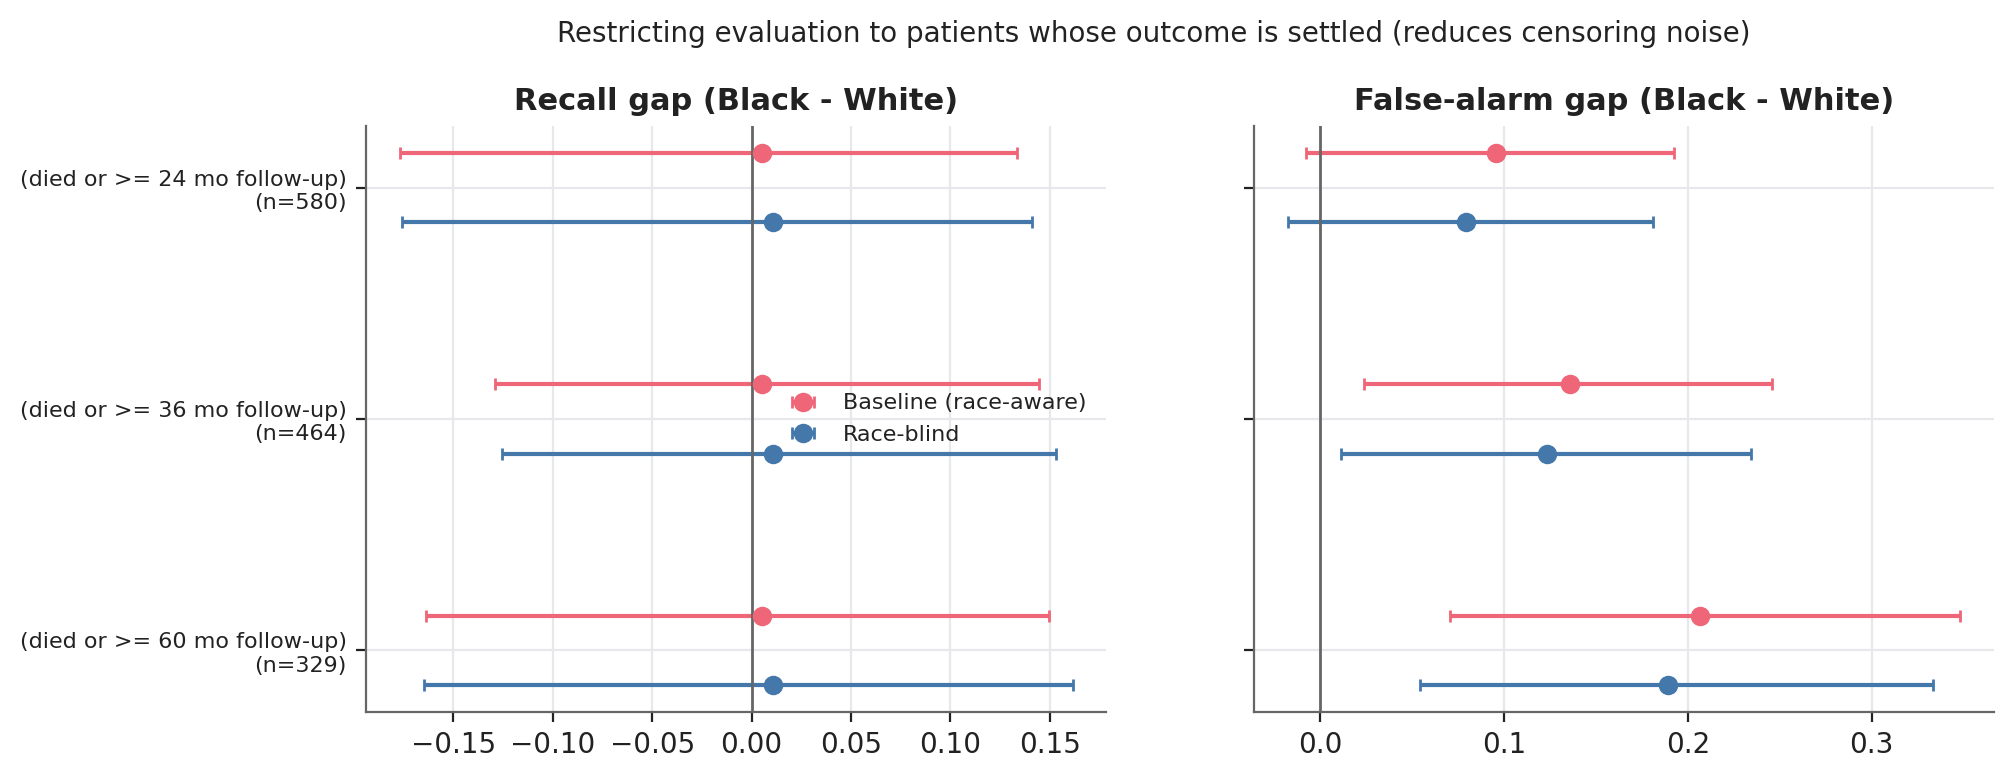

In [15]:
s.sensitivity()
display(s.sensitivity_table[s.sensitivity_table.metric.isin(["tpr_gap", "fpr_gap"]) & s.sensitivity_table.strategy.isin(["aware", "blind", "reweigh"])].round(3))
display(s.ancestry_table.round(3))
plots.fig_sensitivity(s, FIG); show("11_sensitivity_settled.png", 950)

## 7. SHAP: what does the model look at, and is it the same for both groups?

SHAP values are in log-odds and add up exactly to each patient's score.

[20:03:00] fitting deployment models on the whole cohort ...


[20:03:05] SHAP ...


[20:03:06] SHAP stability bootstrap ...


,feature,expected,spearman,agrees,mean_abs_shap
0,Age at diagnosis,higher -> more risk,0.550,True,0.208
1,Tumour size (T),higher -> more risk,0.709,True,0.083
2,Nodal status (N),higher -> more risk,0.945,True,0.154
3,Distant metastasis (M1),higher -> more risk,1.000,True,0.073


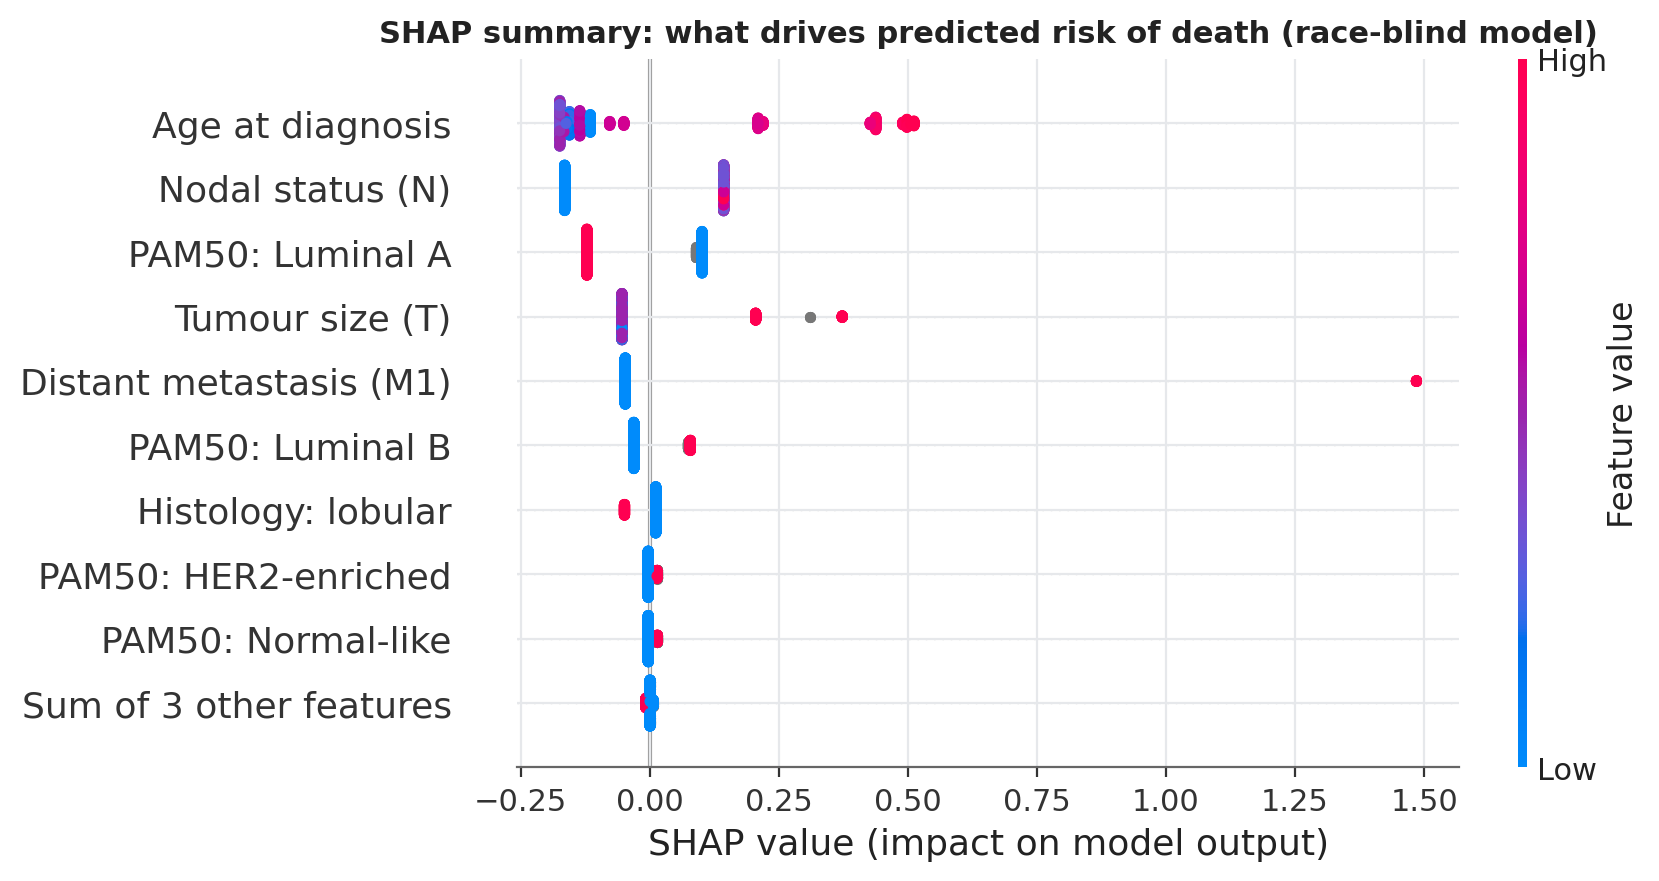

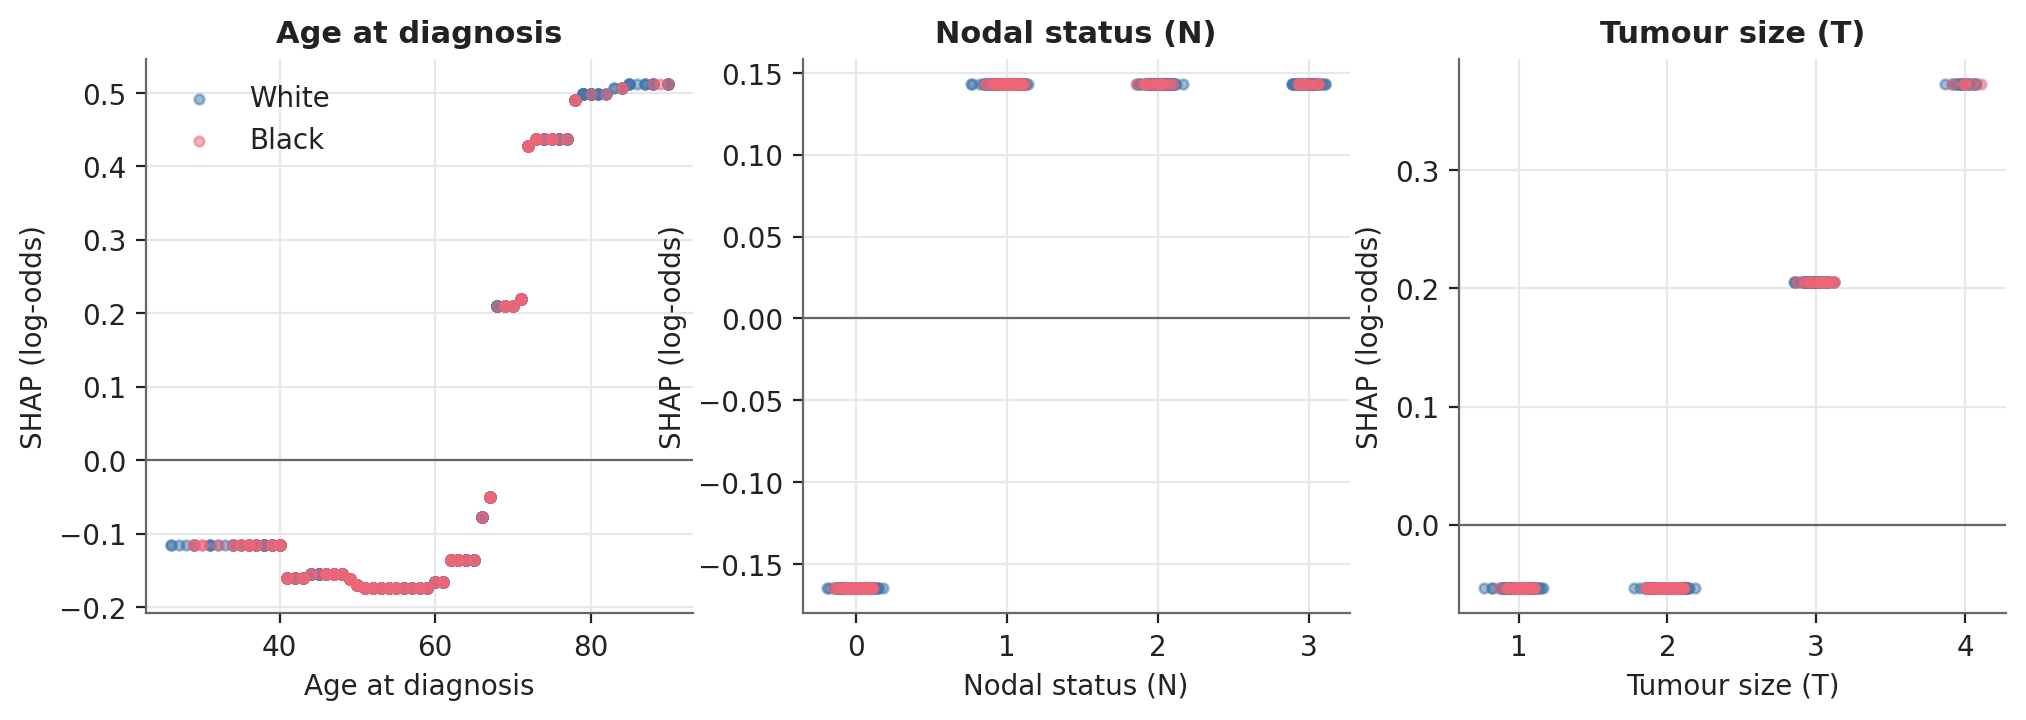

In [16]:
s.final_models(); s.explain()
display(s.direction.round(3))
plots.fig_shap_global(s, FIG); show("12_shap_beeswarm.png", 700)
plots.fig_dependence(s, FIG); show("14_dependence.png", 1000)

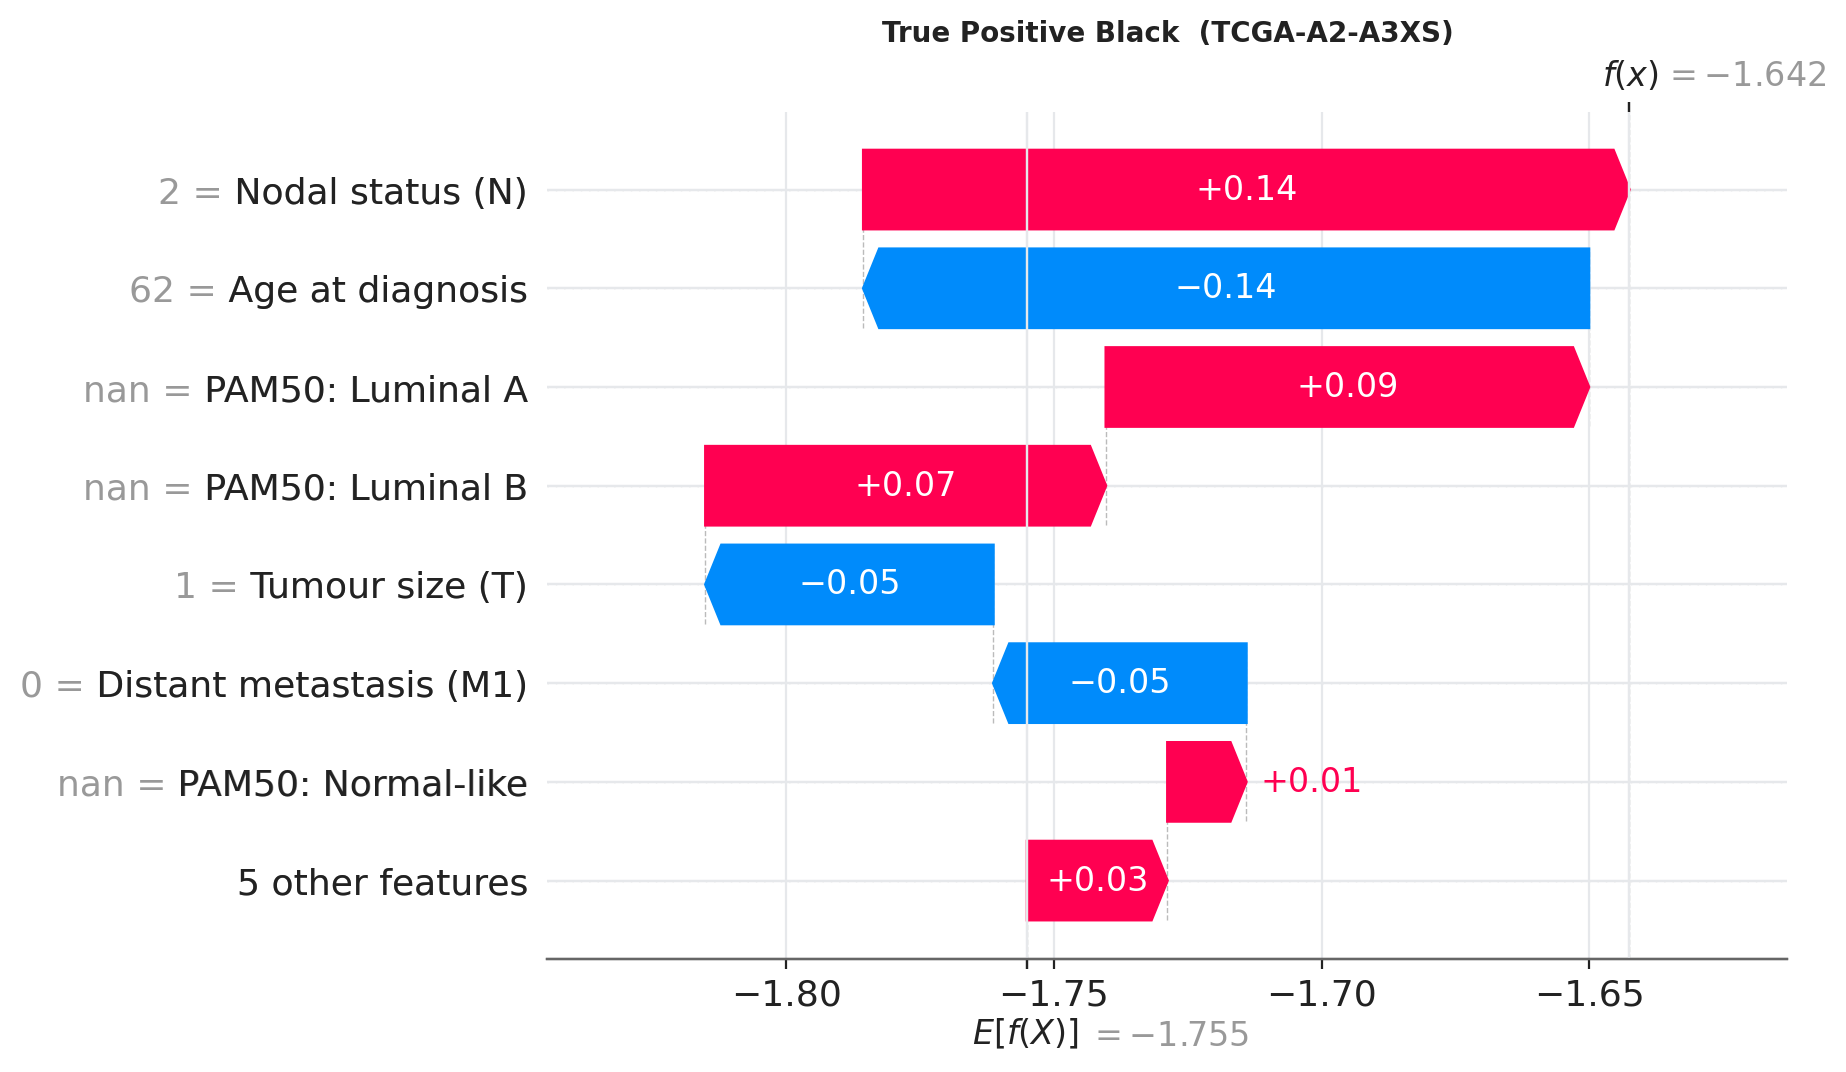

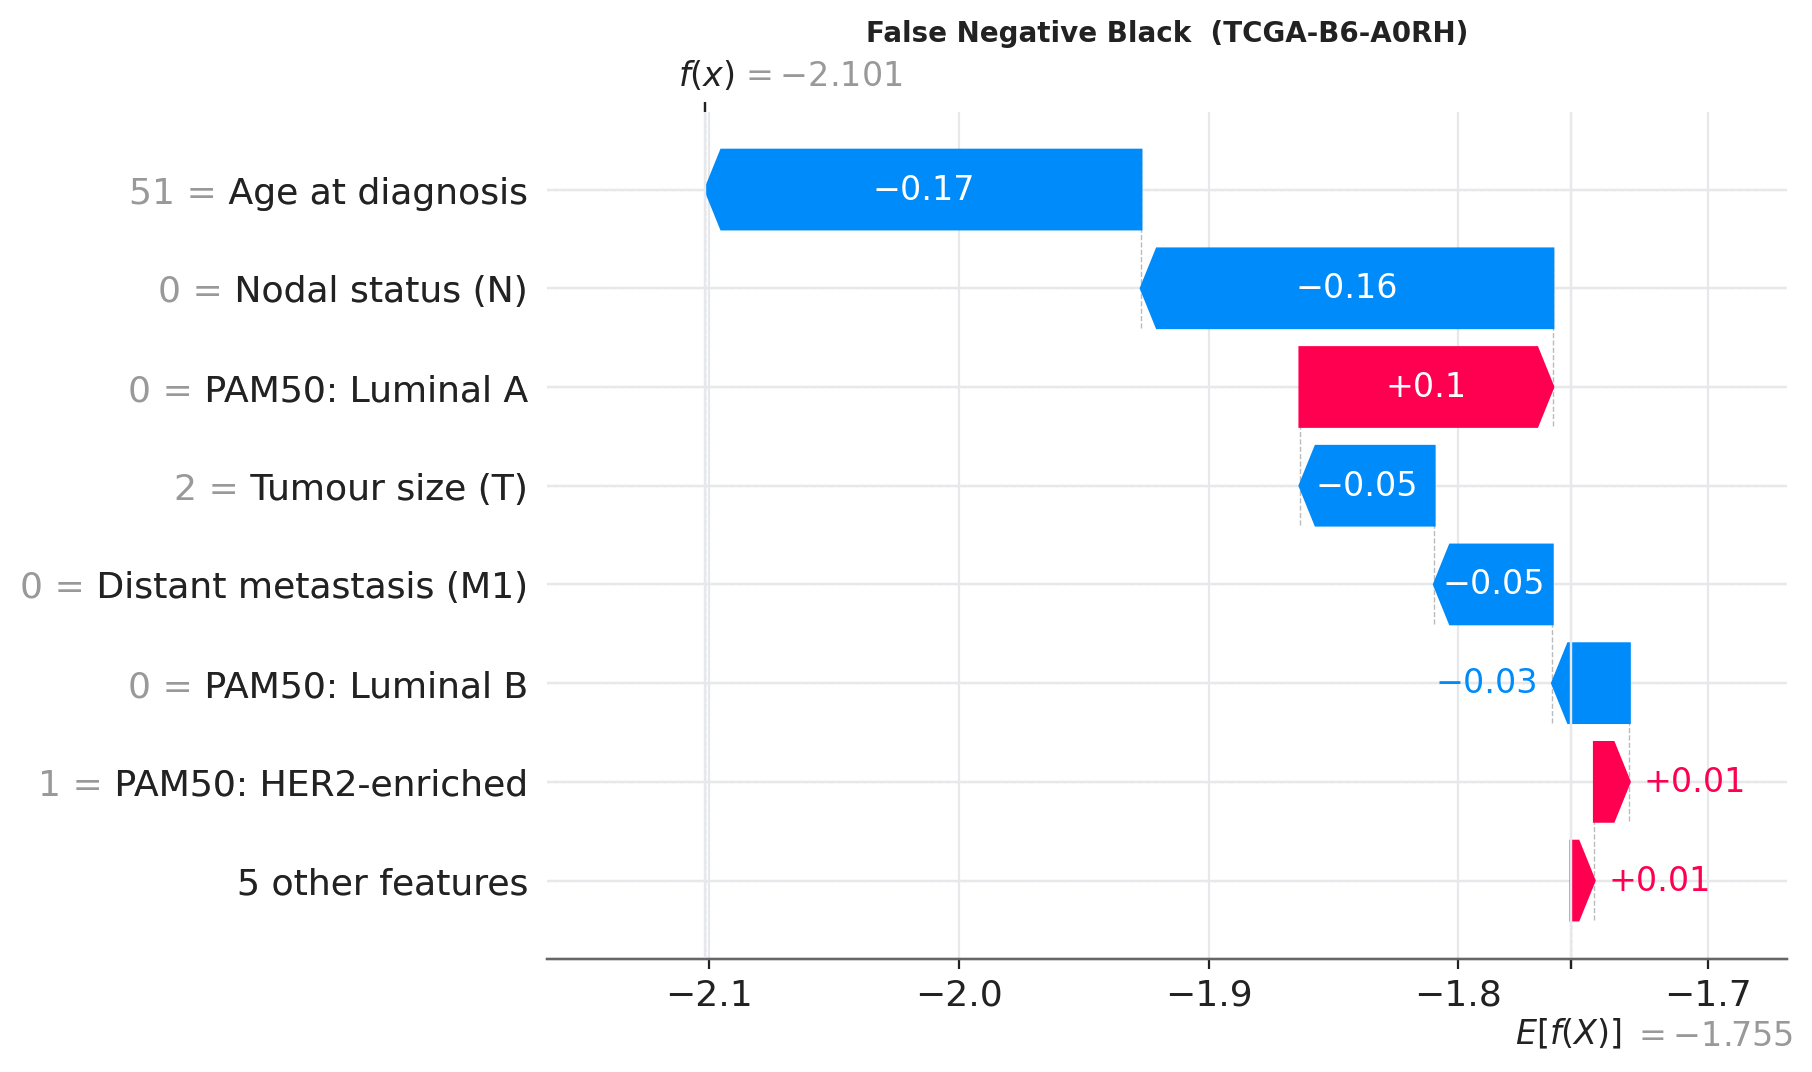

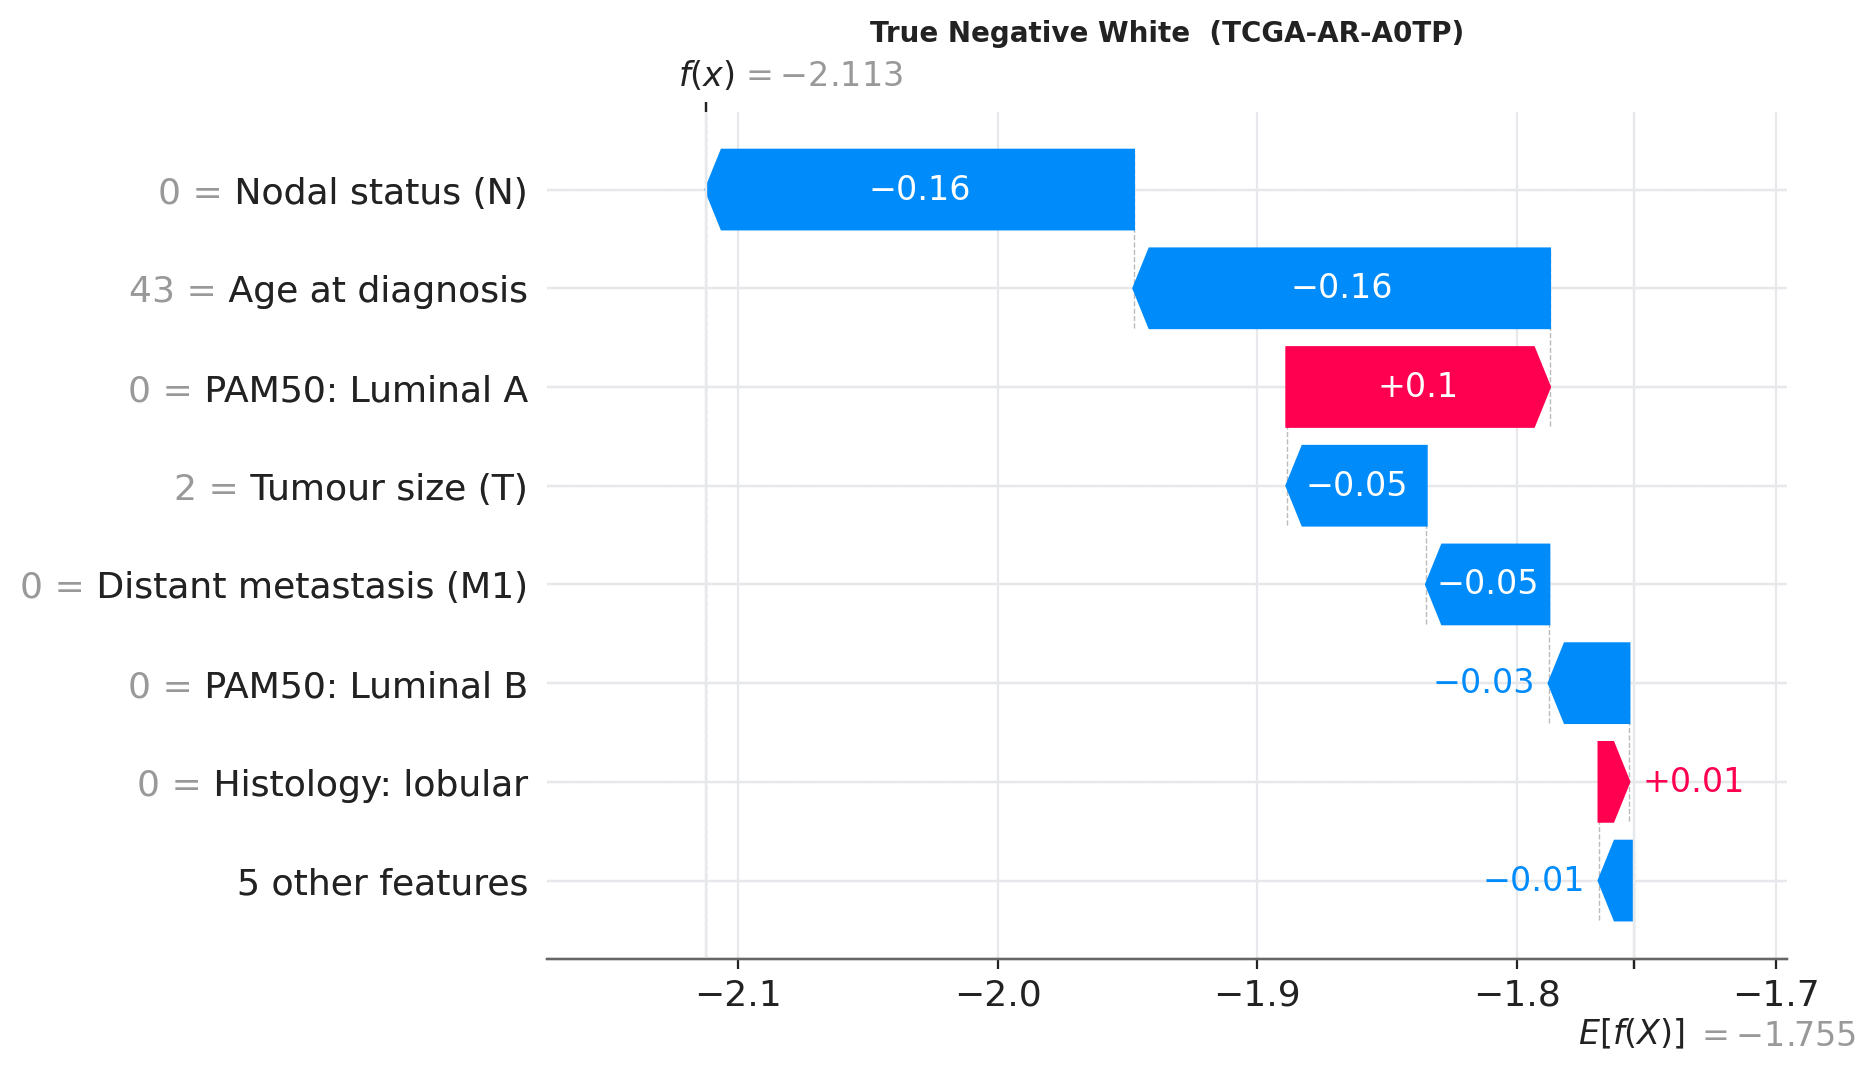

In [17]:
plots.fig_waterfalls(s, FIG)
for n in ["true_positive_black", "false_negative_black", "true_negative_white"]:
    show(f"15_waterfall_{n}.png", 520)

,White,Black,ratio_B_over_W,rank_White,rank_Black,label
age,0.210,0.202,0.963,1,1,Age at diagnosis
n_stage,0.154,0.154,1.005,2,2,Nodal status (N)
sub_luma,0.111,0.106,0.960,3,3,PAM50: Luminal A
t_stage,0.084,0.083,0.992,4,5,Tumour size (T)
m_stage,0.070,0.087,1.235,5,4,Distant metastasis (M1)
sub_lumb,0.043,0.043,1.002,6,6,PAM50: Luminal B
histology_lobular,0.020,0.015,0.761,7,7,Histology: lobular
sub_her2,0.005,0.005,1.151,8,8,PAM50: HER2-enriched
sub_normal,0.004,0.005,1.125,9,9,PAM50: Normal-like
sub_basal,0.002,0.003,1.404,10,10,PAM50: Basal-like


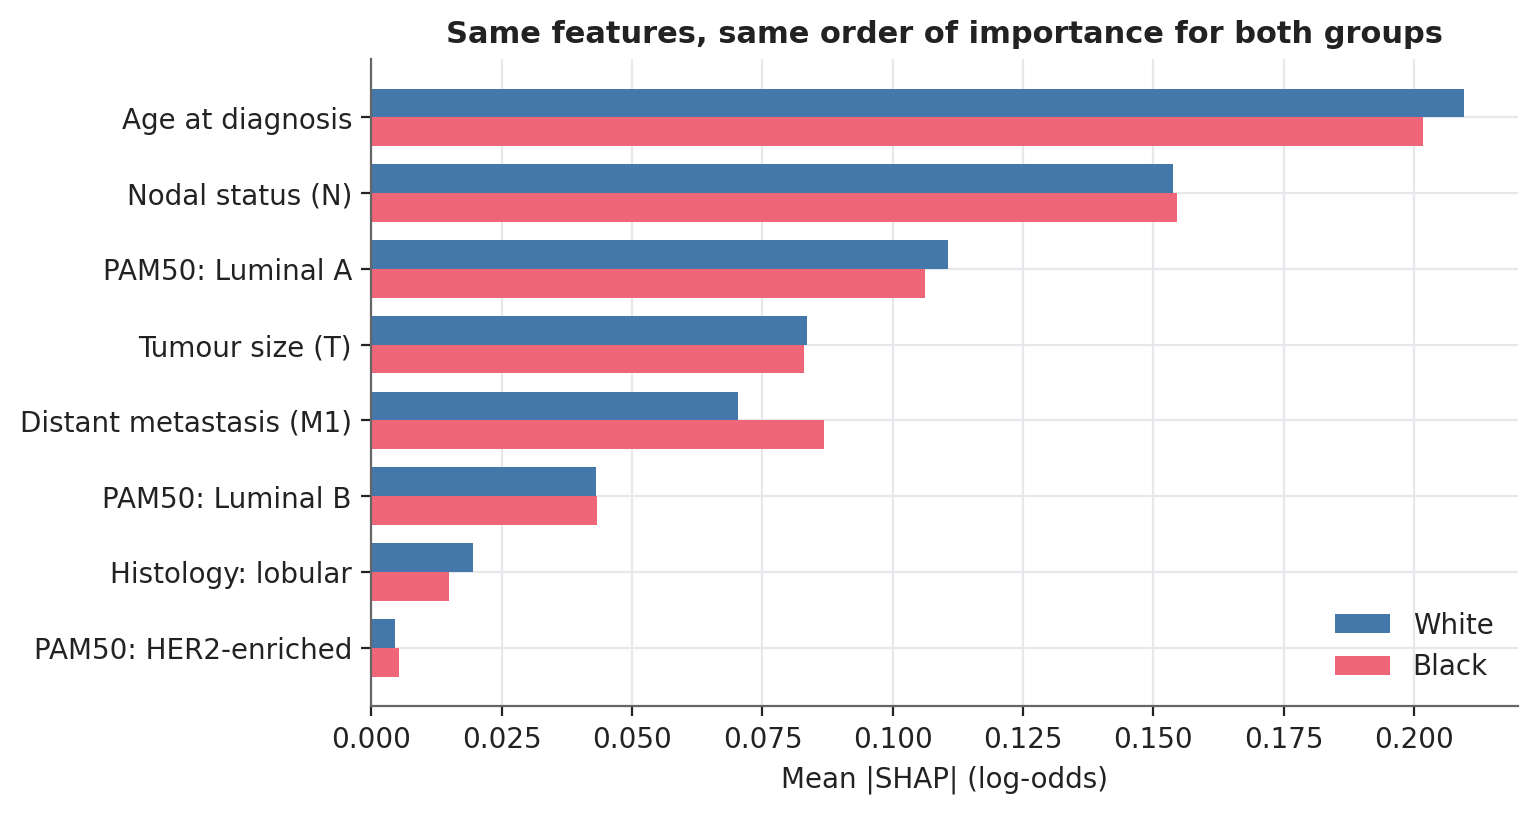

,mean_shap_White,mean_shap_Black,contribution_to_gap,label
sub_luma,-0.014,0.031,0.045,PAM50: Luminal A
m_stage,-0.023,-0.005,0.018,Distant metastasis (M1)
age,-0.018,-0.030,-0.012,Age at diagnosis
n_stage,-0.008,-0.018,-0.010,Nodal status (N)
histology_lobular,-0.001,0.006,0.008,Histology: lobular
t_stage,-0.006,-0.009,-0.002,Tumour size (T)
sub_basal,0.000,-0.001,-0.001,PAM50: Basal-like
sub_her2,-0.000,0.001,0.001,PAM50: HER2-enriched
sub_normal,-0.000,0.000,0.001,PAM50: Normal-like
sub_lumb,-0.002,-0.002,0.000,PAM50: Luminal B


total gap in mean log-odds: 0.046


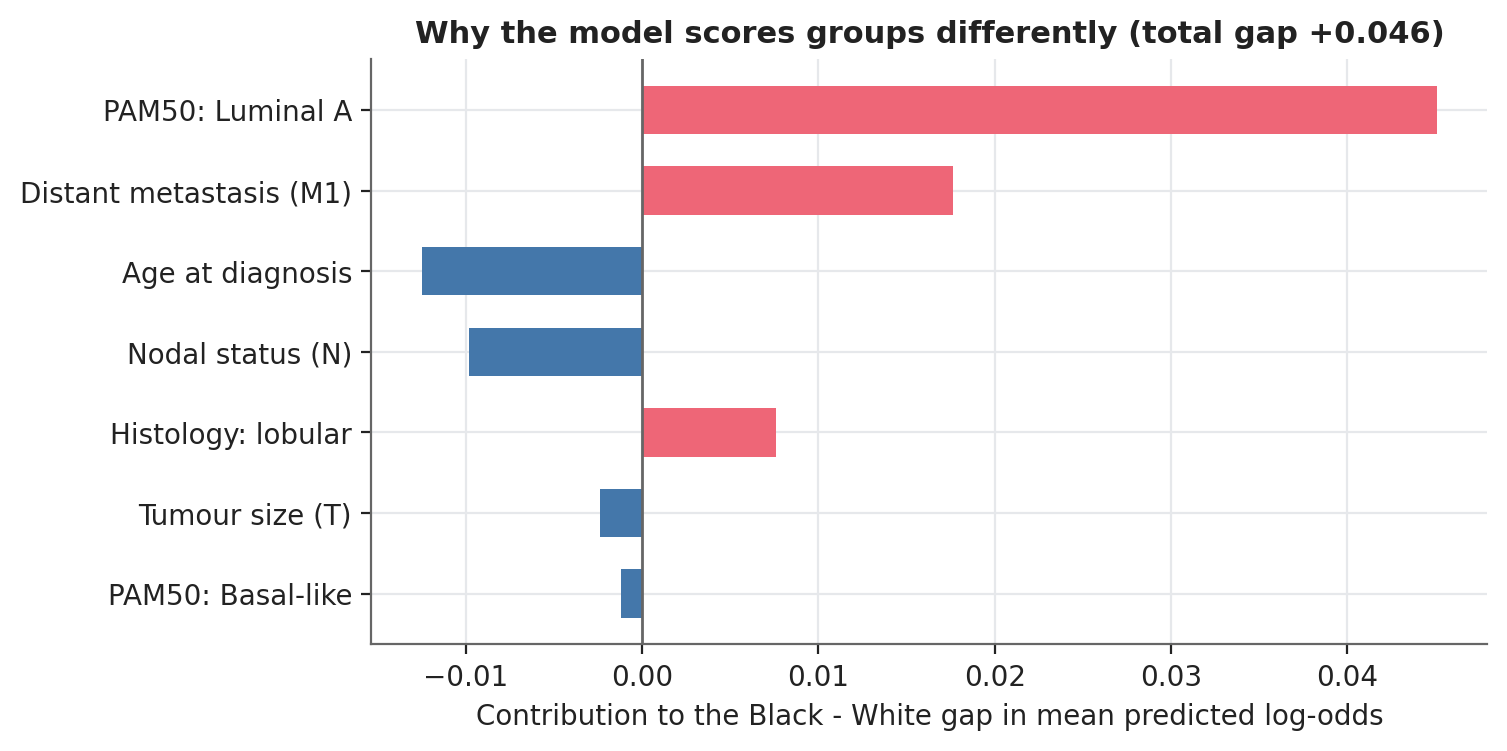

In [18]:
display(s.imp_group.round(3))
plots.fig_importance_group(s, FIG); show("13_importance_by_race.png", 650)
display(s.gap_decomp.round(3)); print("total gap in mean log-odds:", round(s.gap_decomp.attrs["total_gap"], 3))
plots.fig_gap_decomp(s, FIG); show("16_risk_gap_decomposition.png", 650)

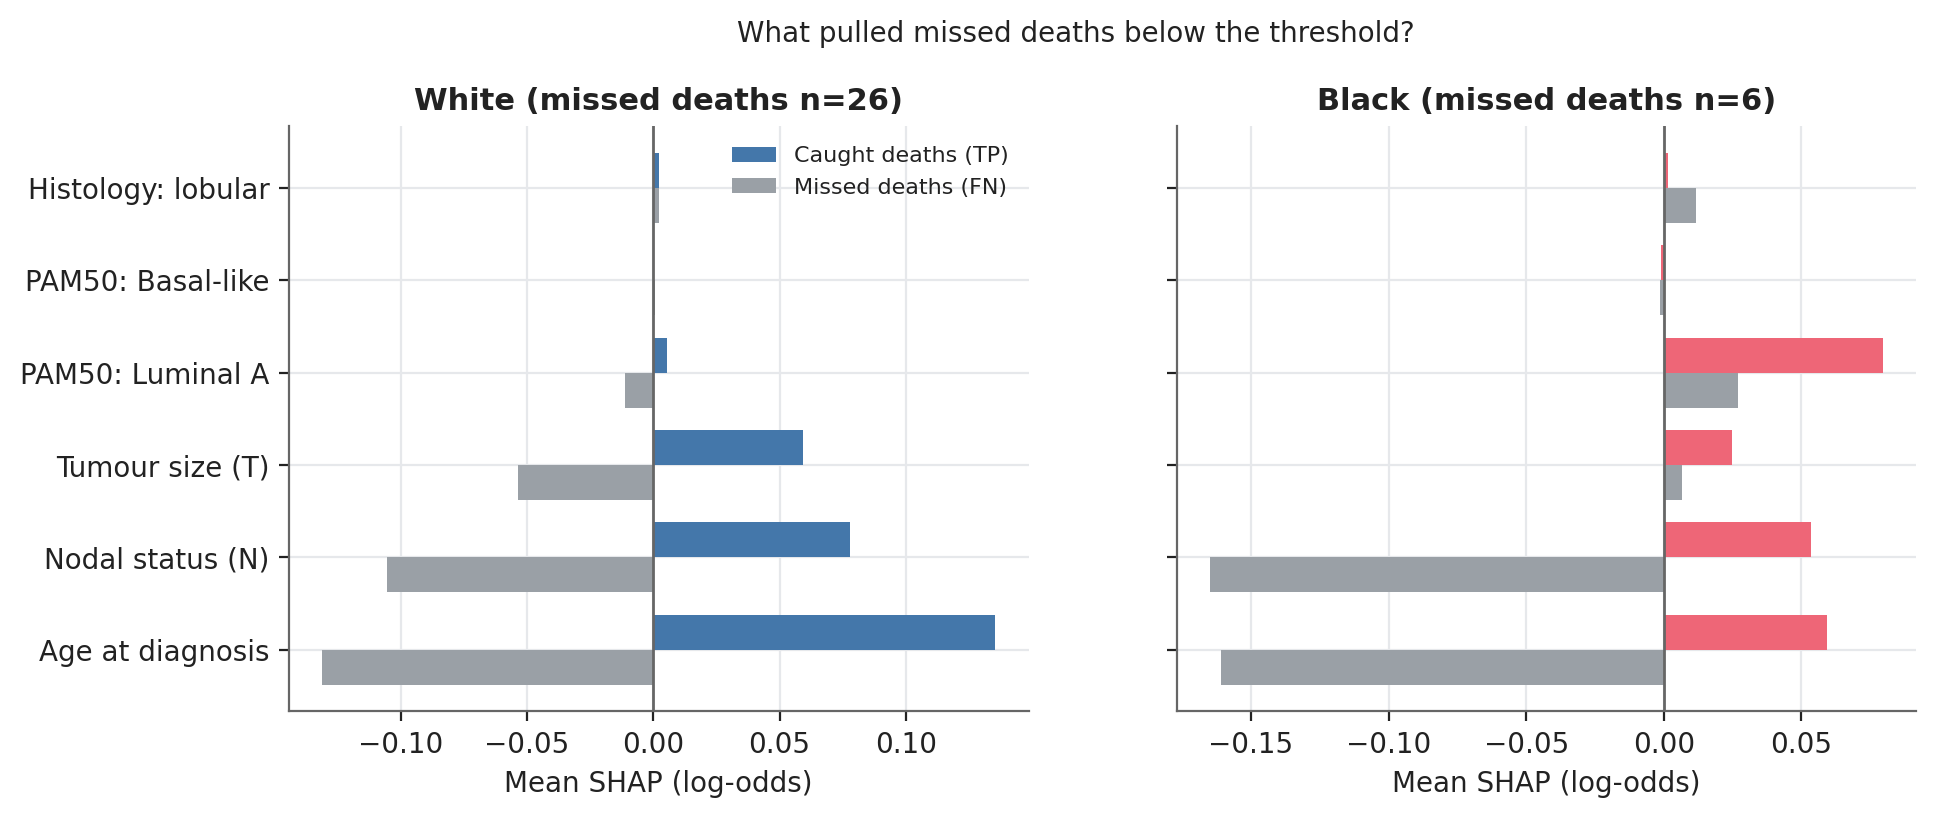

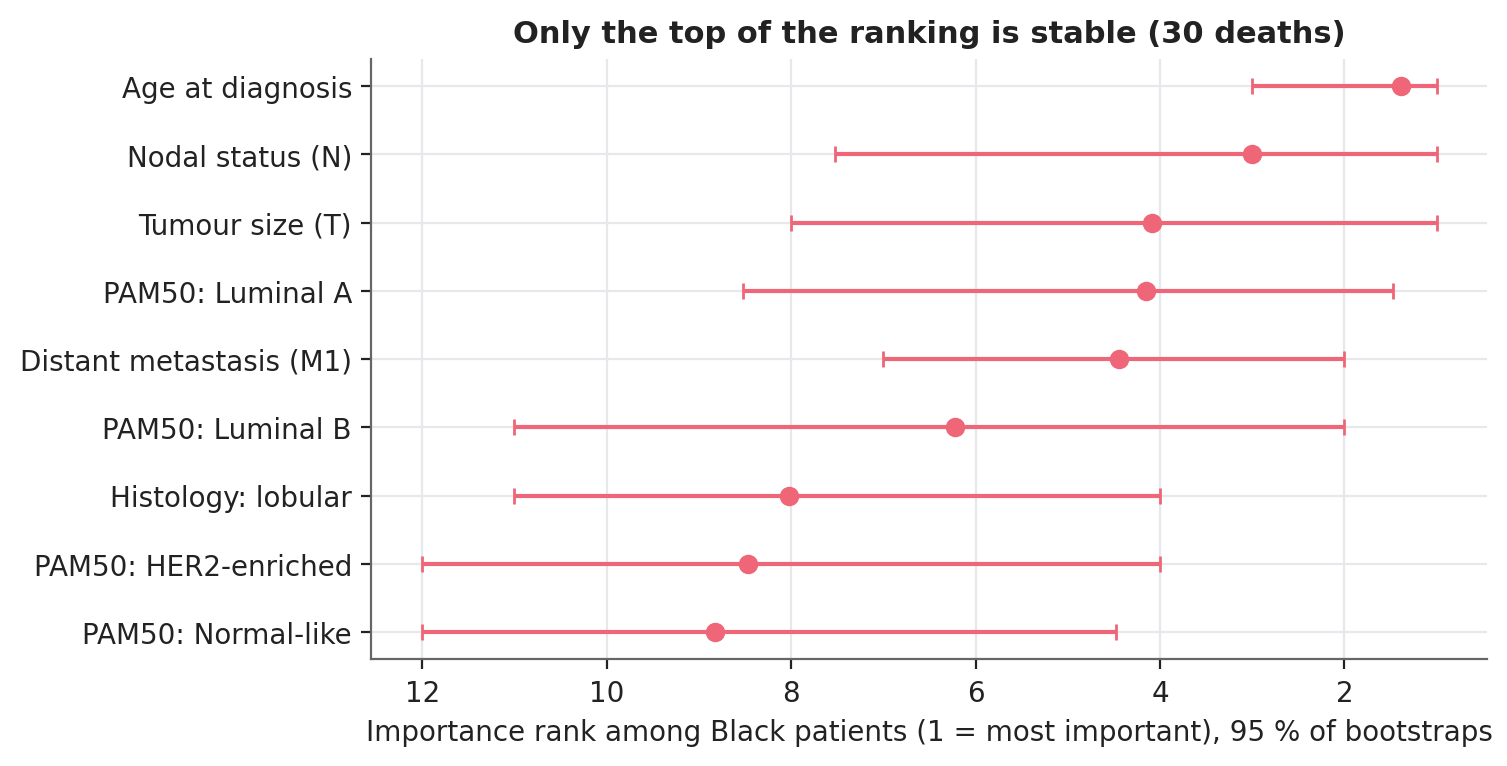

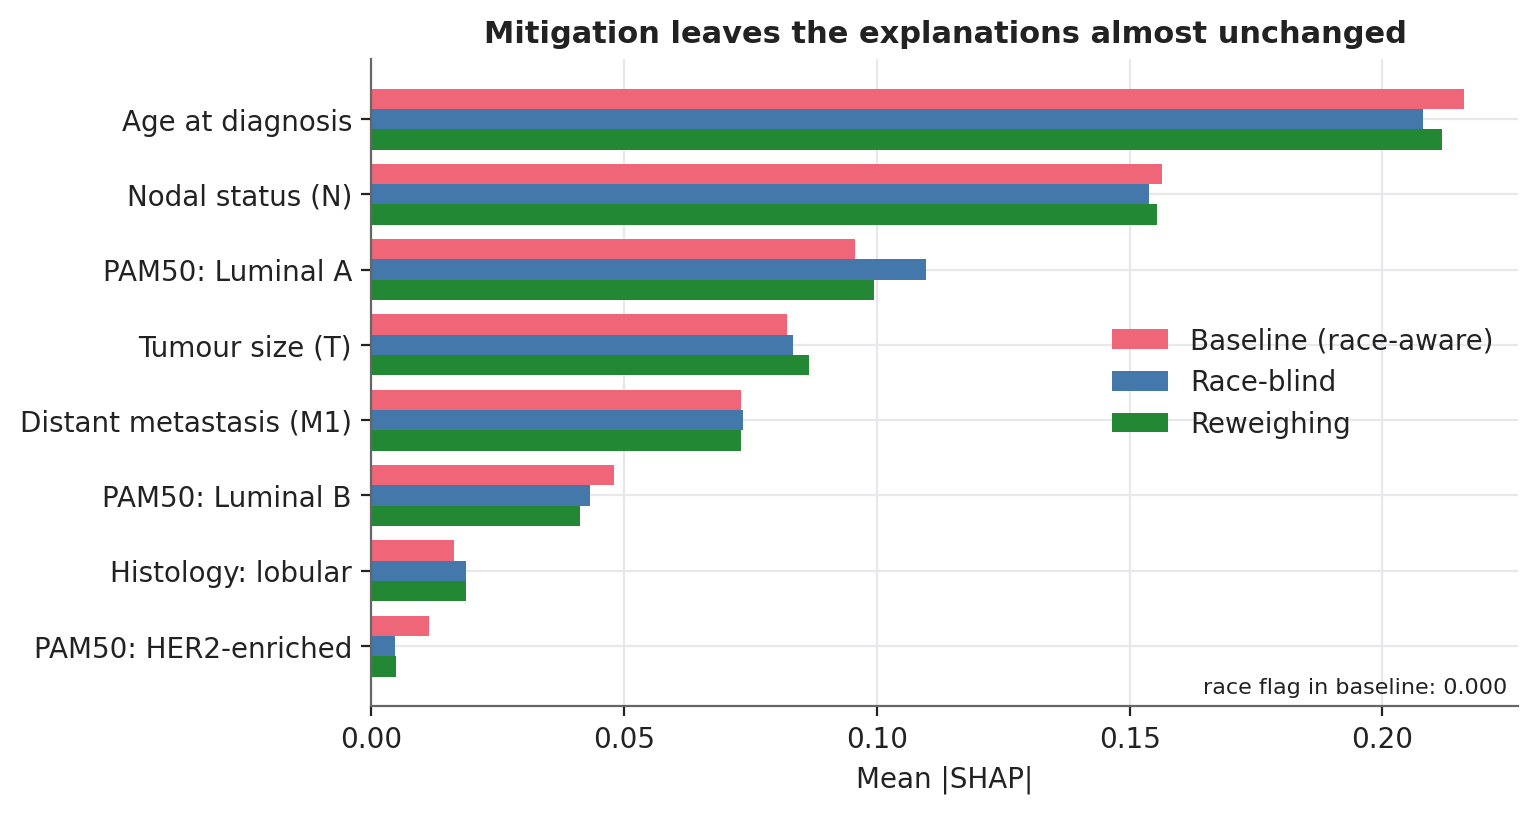

{'blind_vs_aware': {'rank_corr': 0.99124495269876, 'per_patient_rank_corr': 0.9921814854104424}, 'blind_vs_reweigh': {'rank_corr': 1.0, 'per_patient_rank_corr': 0.9982797950712391}}


In [19]:
plots.fig_profile(s, FIG); show("17_missed_deaths_profile.png", 950)
plots.fig_stability(s, FIG); show("18_shap_stability_black.png", 650)
plots.fig_mitigation_explanations(s, FIG); show("19_explanations_under_mitigation.png", 650)
print(s.agreement)

## 8. Save artifacts, figures and the cache the dashboard needs

In [20]:
import joblib
s.save(); plots.make_all(s); joblib.dump(s, ROOT / "artifacts" / "_study.joblib")
print(sorted(p.name for p in (ROOT / "artifacts").iterdir())[:40])

[20:03:29] writing artifacts to C:\Users\Segun\Documents\GitHub\explainable-breast-cancer\artifacts ...


['_study.joblib', 'auc_by_group.csv', 'calibration_by_group.csv', 'cohort.csv', 'cohort_shap.csv', 'column_governance.csv', 'cv_thresholds.csv', 'decision_profile.csv', 'fairness_cv_summary.csv', 'fairness_paired_vs_aware.csv', 'holdout_by_group.csv', 'importance_black_vs_white.csv', 'importance_by_model.csv', 'leakage_ladder.csv', 'meta.json', 'missingness_audit.csv', 'model_benchmark.csv', 'recall_target_sweep.csv', 'risk_gap_decomposition.csv', 'roc_by_group.csv', 'sensitivity_ancestry.csv', 'sensitivity_settled_outcome.csv', 'shap_direction_check.csv', 'stability_black.csv', 'table1.csv', 'tuning_results.csv', 'xgb_aware.json', 'xgb_blind.json', 'xgb_reweigh.json']


In [21]:
h = s.res["cv"]
say("### Findings (generated)\n"
    f"* Race-blind model, recall target {h['target_recall']:.0%}: recall {h['blind']['tpr_all']:.1%}, false-positive rate {h['blind']['fpr_all']:.1%}, "
    f"{h['blind']['flag_all']:.0%} of patients flagged.\n"
    f"* Equal-opportunity gap (baseline): {h['aware']['tpr_gap']:+.3f}, CI {h['aware']['tpr_gap_ci'][0]:+.3f} to {h['aware']['tpr_gap_ci'][1]:+.3f}.\n"
    f"* False-alarm gap: baseline {h['aware']['fpr_gap']:+.3f}; reweighing {h['reweigh']['fpr_gap']:+.3f}; group thresholds {h['gthr']['fpr_gap']:+.3f}.\n"
    f"* Black-patient AUC {s.auc_group.query('strategy==\"blind\" and group==\"Black\"').auc.iloc[0]:.2f} vs White {s.auc_group.query('strategy==\"blind\" and group==\"White\"').auc.iloc[0]:.2f}.")

### Findings (generated)
* Race-blind model, recall target 80%: recall 79.1%, false-positive rate 63.0%, 65% of patients flagged.
* Equal-opportunity gap (baseline): +0.005, CI -0.141 to +0.156.
* False-alarm gap: baseline +0.050; reweighing +0.037; group thresholds +0.042.
* Black-patient AUC 0.65 vs White 0.66.